In [15]:
import torch
import matplotlib.pyplot as plt
import os
import time
import numpy as np
import pandas as pd
import random
from matplotlib.patches import Rectangle
import tifffile
import h5py
from torch.utils.data import DataLoader
import imageio.v2 as imageio
from scipy.ndimage import gaussian_filter
from matplotlib.patches import Patch

import importlib as imp
import sys
sys.path.append(os.path.join(os.path.split(os.getcwd())[0], 'scripts'))

import yolo_tiles
imp.reload(yolo_tiles)
from yolo_tiles import img_to_tiles, apply_model_to_tiles, load_test_image, preprocess, tileDataset, remove_bbox_in_overlap

import yolo_help
imp.reload(yolo_help)
from yolo_help import bbox_to_rectangles, imshow, convert_data, Net, get_best_bounding_box_per_cell

import yolo_post_help
imp.reload(yolo_post_help)
from yolo_post_help import postprocess, bb_to_rec, NMS

import yolo_help_3D
imp.reload(yolo_help_3D)
from yolo_help_3D import apply_model_to_orthogonal_slices, gen_3D_GT, recon_down, vol_to_mip_rgb, orthogonal_to_3D, vol_to_mip

import yolo_avg_prec
imp.reload(yolo_avg_prec)
from yolo_avg_prec import get_AP, gt_bbox_to_pred_bbox_format, IOU_3D, yolo_output_to_list

import yolo_3D_pipeline_help
imp.reload(yolo_3D_pipeline_help)
from yolo_3D_pipeline_help import apply_2D_yolo_to_slices, stitch_slices_into_cube

import equiv_3D_pipeline_help
imp.reload(equiv_3D_pipeline_help)
from equiv_3D_pipeline_help import apply_2D_equiv_to_slices

import nibabel as nib
from csbdeep.utils import normalize

from stardist.models import StarDist3D
from cellpose import models

pd.set_option('display.max_rows', 500)
pd.set_option('display.max_columns', 500)


sys.path.append('/home/abenneck/equivariance_model')
import moment_kernels as mk
imp.reload(mk)

<module 'moment_kernels' from '/home/abenneck/equivariance_model/moment_kernels.py'>

In [2]:
def bb_slice_filter(all_bb, ax_idx, slice_val):
    """
    NOTE: Each elem of all_bb should have at minimum these first 6 values [ax0_min, ax0_max, ax1_min, ax1_max, ax2_min, ax2_max, ...]
    """
    bb_out = []
    for bb in all_bb:
        if ax_idx == 0 and bb[0] <= slice_val and bb[1] >= slice_val:
            bb_out.append(bb)
        elif ax_idx == 1 and bb[2] <= slice_val and bb[3] >= slice_val:
            bb_out.append(bb)
        elif ax_idx == 2 and bb[4] <= slice_val and bb[5] >= slice_val:
            bb_out.append(bb)
        else:
            continue

    if bb_out == []:
        return np.array([])
    return np.stack(bb_out, axis=0)

# def gt_mask_to_bb_list(mask_path, verbose=False):
#     """
#     Converts an integer-valued array into a set of bounding boxes around each unique instance.
#     """
#     # Load the GT annotation
#     mask = nib.load(mask_path)
    
#     # 0: Bg, 1: Annotated bg, 2+: Cell ID
#     gt_bb = []
#     vals_to_skip = [0, 1]
#     n_cells = len(np.unique(mask.get_fdata())) - 2 # 0 is bg and 1 is annotated bg
#     for val in np.unique(mask.get_fdata()):
#         if val in vals_to_skip:
#             continue
#         mask_cell = np.copy(mask.get_fdata())
#         mask_cell[mask_cell != val] = 0.0
#         mask_cell[mask_cell == val] = 1.0
#         if verbose:
#             print(f'Cell {(val-1).astype(int)} / {n_cells} volume of {np.sum(mask_cell).astype(int)} voxels')
#         all_x, all_y, all_z = np.where(mask_cell == 1.0)
#         gt_bb.append([min(all_x).item(), max(all_x).item(), min(all_y).item(), max(all_y).item(), min(all_z).item(), max(all_z).item(), int(val)])

#     return gt_bb

def gt_mask_to_bb_list(mask, verbose=False):
    """
    Converts an integer-valued array into a set of bounding boxes around each unique instance.
    (10/19/26) Changed input from 'mask_path' to 'mask'
    """
    # 0: Bg, 1: Annotated bg, 2+: Cell ID
    gt_bb = []
    vals_to_skip = [0, 1]
    n_cells = len(np.unique(mask)) - 2 # 0 is bg and 1 is annotated bg
    for val in np.unique(mask):
        if val in vals_to_skip:
            continue
        mask_cell = np.copy(mask)
        mask_cell[mask_cell != val] = 0.0
        mask_cell[mask_cell == val] = 1.0
        if verbose:
            print(f'Cell {(val-1).astype(int)} / {n_cells} volume of {np.sum(mask_cell).astype(int)} voxels')
        all_x, all_y, all_z = np.where(mask_cell == 1.0)
        gt_bb.append([min(all_x).item(), max(all_x).item(), min(all_y).item(), max(all_y).item(), min(all_z).item(), max(all_z).item(), int(val)])

    return gt_bb

def yolo_output_to_bb_list(out):
    return out.reshape(out.shape[0]*out.shape[1]*out.shape[2],out.shape[3])

def stardist_to_bb_list(raw_output, mode='2D'):
    """
    Converts a standard output from the 2D or 3D StarDist models to a set of bounding boxes
    """

    bb_out = []
    if mode == '2D':
        for i in range(len(raw_output['coord'])):
            coords = raw_output['coord'][i]
            center = raw_output['points'][i]
            prob = float(raw_output['prob'][i])
    
            xmin = float(min(coords[1]))
            xmax = float(max(coords[1]))
            ymin = float(min(coords[0]))
            ymax = float(max(coords[0]))
    
            bb_out.append([xmin, xmax, ymin, ymax, prob])
    elif mode == '3D':
        n_ray = raw_output['dist'].shape[1]
        n_cells = raw_output['dist'].shape[0]
        n_dim = raw_output['points'].shape[1]
        for i in range(n_cells):
            prob = raw_output['prob'][i]
            center = raw_output['points'][i]
            n_vectors = [raw_output['rays_vertices'][j]*raw_output['dist'][i][j] for j in range(n_ray)]
            n_vectors = np.asarray(n_vectors) + center
        
            xmin, ymin, zmin = np.min(n_vectors, axis=0)
            xmax, ymax, zmax = np.max(n_vectors, axis=0)
        
            bb_out.append([xmin, xmax, ymin, ymax, zmin, zmax, prob])
    else:
        print(f'Invalid mode - {mode}; Expected 2D or 3D')
        
    return np.asarray(bb_out)

def cellpose_to_bb_list(mask, verbose=False):
    """
    Converts an integer-valued array into a set of bounding boxes around each unique instance.

    Output bbox format: [xmin xmax ymin ymax zmin zmax cell# conf]
    """
    # 0: Bg, 1+: Cell ID
    bb_out = []
    vals_to_skip = [0]
    n_cells = len(np.unique(mask)) - 1 # 0 is bg
    for val in np.unique(mask):
        if val in vals_to_skip:
            continue
        mask_cell = np.copy(mask)
        mask_cell[mask_cell != val] = 0.0
        mask_cell[mask_cell == val] = 1.0
        if verbose:
            print(f'Cell {(val-1).astype(int)} / {n_cells} volume of {np.sum(mask_cell).astype(int)} voxels')
        all_x, all_y, all_z = np.where(mask_cell == 1.0)
        bb_out.append([min(all_x).item(), max(all_x).item(), min(all_y).item(), max(all_y).item(), min(all_z).item(), max(all_z).item(), int(val), 1.0])
    return np.array(bb_out)

def preprocess_3D(img, upsample = True, gamma = True, norm = True):

    img_out = np.copy(img)
    
    # Apply a gamma correction (gamma = 1/2)
    if gamma:
        img_out = img_out**(1/2)

    # Normalize the image to [0,1]
    if normalize:
        # img_min = np.min(img,axis=(-1,-2,-3),keepdims=True)
        # img_max = np.max(img,axis=(-1,-2,-3),keepdims=True)
        # img_out = (img_out - img_min) / (img_max - img_min)
        img_out = normalize(img_out)
        
    # Upsample the image by a factor of 2 (Inc the size of each voxel from 1 to 2x2x2)
    if upsample:
        out_shape = [i*2 for i in img.shape]
        img_up = np.zeros(out_shape)
    
        img_up[::2,::2,::2]   = img_out
        img_up[::2,1::2,::2]  = img_out
        img_up[1::2,::2,::2]  = img_out
        img_up[1::2,1::2,::2] = img_out
        
        img_up[::2,::2,1::2]   = img_out
        img_up[::2,1::2,1::2]  = img_out
        img_up[1::2,::2,1::2]  = img_out
        img_up[1::2,1::2,1::2] = img_out

        img_out = img_up

    return img_out

# Convert all bb coords in 'bb_list' to the appropriate coordinate space (relative to the annotated region, with origin in the upper left corner)
def convert_bb_units(bb_list):
    bb_out = []
    for bb in bb_list:
        new_bb = [2*(val-96) for val in bb[:6]]
        new_bb.extend(bb[6:])
        bb_out.append(new_bb)
    return np.array(bb_out)

def remove_low_conf_bb(data, conf_idx = -4):
    """
    Remove all bboxes with a conf of 0, so that they won't be considered when computing AP
    """
    data_out = []
    for i, row in enumerate(data):
        if row[conf_idx] > 0:
            data_out.append(row)
    return np.array(data_out)

# Remove bboxes which lie entirely outside of 'bounds' along all 3 axes
def trim_bb(bb, bounds = [-0.5,127.5]):
    # only keep the boxes that are inside
    inds = np.all(bb[...,[1,3,5]] > bounds[0], 1) # these are the right sides
    
    # and the left sides
    inds *= np.all( bb[...,[0,2,4]] < bounds[1], 1)

    bb = bb[inds]
    return bb

In [137]:
# Apply some combinations of transformations to permute "vol"
def permute_vol(vol, flips, perm=0):
    """
    vol : array[float32] of shape N x N x N
        The target volume which should be flipped + permuted
    flips : array[bool] of shape 1 x 3
        if flips[i] is True, flip vol along ax i 
    perm : int
        Default - 0 (No permutation); The index of the permutation
    """

    # Flip along axis 0, 1, and/or 2 based on the boolean values in "flips"
    if flips[0]:
        vol = np.flip(vol, axis = 0)
    if flips[1]:
        vol = np.flip(vol, axis = 1)
    if flips[2]:
        vol = np.flip(vol, axis = 2)

    # Permute the volume
    permutations = [[0,1,2], [0,2,1], [1,0,2], [1,2,0], [2,0,1], [2,1,0]]
    permuted_vol = np.transpose(vol, axes=permutations[perm])
    
    return permuted_vol

def reverse_perm(bb_in, flips=[False,False,False], perm=0, dim = 128):
    """
    bb_in : ndarray
        A list of bounding boxes where each element is of the form [slicemin, slicemax, rowmin, rowmax, colmin, colmax, ...]
    flips : array[bool] of shape 1 x 3
        The axes along which the input was flipped BEFORE being processed
    perm : int
        The same index that was passed in permute_vol(...)
    dim : int
        The size of the volume just before being processed (Original input (s=256), Upsampled annotated region (s=128))
    """

    # Apply the inverse permutation
    if perm == 0: # Forward: [0,1,2]
        bb_out = bb_in[:,[0,1,2,3,4,5]]
    elif perm == 1: # Forward: [0,2,1]
        bb_out = bb_in[:,[0,1,4,5,2,3]]
    elif perm == 2: # Forward: [1,0,2]
        bb_out = bb_in[:,[2,3,0,1,4,5]]
    elif perm == 3: # Forward: [1,2,0]
        # bb_out = bb_in[:,[2,3,4,5,0,1]]
        bb_out = bb_in[:,[4,5,0,1,2,3]]
    elif perm == 4: # Forward: [2,0,1]
        # bb_out = bb_in[:,[4,5,0,1,2,3]]
        bb_out = bb_in[:,[2,3,4,5,0,1]]
    elif perm == 5: # Forward: [2,1,0]
        bb_out = bb_in[:,[4,5,2,3,0,1]]
    else:
        raise Exception(f'Invalid argument supplied for \'perm\' - ({perm}). Argument must be from [0,1,2,3,4,5]')

    # If necessary, append other bbox values back onto the list of bboxes (i.e. conf or class probabilities)
    if len(bb_in[0]) > 6:
        bb_out = np.concatenate([bb_out, bb_in[:,6:]], axis=1)

    # Flip along axis 0, 1, and/or 2 based on the boolean values in "flips"
    if flips[0]:
        bb_out[:,0] = (dim-1) - bb_out[:,0]
        bb_out[:,1] = (dim-1) - bb_out[:,1]
        bb_out[:,[0,1]] = bb_out[:,[1,0]]
    if flips[1]:
        bb_out[:,2] = (dim-1) - bb_out[:,2]
        bb_out[:,3] = (dim-1) - bb_out[:,3]
        bb_out[:,[2,3]] = bb_out[:,[3,2]]
    if flips[2]:
        bb_out[:,4] = (dim-1) - bb_out[:,4]
        bb_out[:,5] = (dim-1) - bb_out[:,5]
        bb_out[:,[4,5]] = bb_out[:,[5,4]]
        
    return bb_out

def add_bbox_info(df, col_label, bbox_data, pred_labels = None):
    if col_label == "GT":
        for gt_bb_ in bbox_data:
            cell_label = gt_bb_[-1]
            df_idx = df.index[df["Cell ID"] == f'{cell_label}'][0]
            df.at[df_idx, "GT"] = gt_bb_[:-1]
    else:
        for i, label in enumerate(pred_labels):
            cell_label = int(label+2) # '+2' offset from cell ID (Annotations start at 2; pred_label starts at 0)
            if cell_label < 2:
                break
            df_idx = df.index[df["Cell ID"] == f'{cell_label}'][0]
            df.at[df_idx, col_label] = f'{np.round(bbox_data[i, :6], decimals=2)}' # (11/03/26) Save as str, needed for dtype compatability
    return

# (0) Load all the models, the target volume, and the associated annotation

In [17]:
# Load the YOLO model
model_path = '/home/abenneck/mounts/bmaproot/nafs/shattuck/RodentToolsData/ZW-DT-1-P56-1/yolo_saved_weights/modelsave_bright_on_dark.pt'
net = Net()
net.load_state_dict(torch.load(model_path))
B = net.B
stride = net.stride
print('Successfully loaded YOLO model . . .')

# Load the Stardist model
star_model = StarDist3D.from_pretrained('3D_demo')
print('Successfully loaded StarDist model . . .')

# Load the Cellpose model (ALL pretrained model weights: ["cpsam_v2" (DEFAULT), "cpdino", "cpdino-vitb", "cpsam"])
cell_model = models.CellposeModel(gpu=False, pretrained_model="cpsam_v2")
print('Successfully loaded CellPose model . . .')

# Load the equivariance model
equiv_path = '/home/abenneck/equivariance_model/training_outputs/eq_weights.pt'
equiv_model = mk.EqNet()
equiv_model.load_state_dict(torch.load(equiv_path))
print('Successfully loaded Equivariant model . . .')

# Load the target volume
indir = os.path.join(os.path.split(os.getcwd())[0], 'inputs')
img_path = os.path.join(indir, 'cube_i0002_j0005_k0003.nii.gz')
img = nib.load(img_path)
img = img.get_fdata()
print('Successfully loaded target volume . . .')

# # Load the GT annotation + convert to list(bbox)
# mask_path = os.path.join(indir, 'mask64_i0002_j0005_k0003_annotated.nii.gz')
# mask = nib.load(mask_path)
# mask = mask.get_fdata()
# gt_bb = gt_mask_to_bb_list(mask_path) # Convert integer-valued img into a list of bboxes
# print(f'Successfully loaded GT annotations ({len(gt_bb)} total cells) . . .')

# Load the GT annotation + convert to list(bbox)
mask_path = os.path.join(indir, 'mask64_i0002_j0005_k0003_annotated.nii.gz')
mask_nib = nib.load(mask_path)
mask = mask_nib.get_fdata()
gt_bb = gt_mask_to_bb_list(mask) # Convert integer-valued img into a list of bboxes
print(f'Successfully loaded GT annotations ({len(gt_bb)} total cells) . . .')

Successfully loaded YOLO model . . .
Found model '3D_demo' for 'StarDist3D'.
Loading network weights from 'weights_best.h5'.
Loading thresholds from 'thresholds.json'.
Using default values: prob_thresh=0.707933, nms_thresh=0.3.
Successfully loaded StarDist model . . .
Successfully loaded CellPose model . . .
Successfully loaded Equivariant model . . .
Successfully loaded target volume . . .
Successfully loaded GT annotations (276 total cells) . . .


### Visualize img + GT annotations

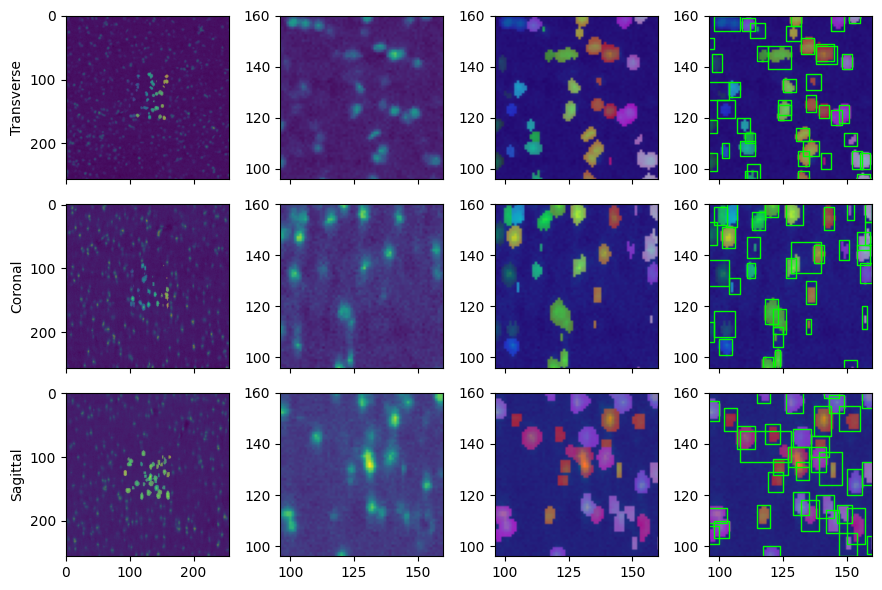

In [34]:
img0 = img[img.shape[0]//2,:,:]
img1 = img[:,img.shape[1]//2,:]
img2 = img[:,:,img.shape[2]//2]

mask0 = mask[mask.shape[0]//2,:,:]
mask1 = mask[:,mask.shape[1]//2,:]
mask2 = mask[:,:,mask.shape[2]//2]

# boundary_mask_path = '/ifshome/abenneck/docs_public/misc_outputs/gt_data/mask64_i0002_j0005_k0003.nii.gz'
boundary_mask = nib.load(mask_path)
boundary_mask = boundary_mask.get_fdata()

boundary_mask0 = boundary_mask[boundary_mask.shape[0]//2,:,:]
boundary_mask1 = boundary_mask[:,boundary_mask.shape[1]//2,:]
boundary_mask2 = boundary_mask[:,:,boundary_mask.shape[2]//2]

lim = [96,160]

fig, axs = plt.subplots(3, 4, layout='tight', sharex='col')
axs[0,0].imshow(img0)
axs[0,0].imshow(boundary_mask0, alpha = 0.5)
axs[0,1].imshow(img0)
axs[0,2].imshow(img0)
axs[0,2].imshow(mask0, cmap = 'gist_ncar', alpha = 0.5)
axs[0,3].imshow(img0)
axs[0,3].imshow(mask0, cmap = 'gist_ncar', alpha = 0.5)
bb_plot = bb_to_rec(bb_slice_filter(gt_bb, 0, img.shape[0]//2), pos = [4, 2, 5, 3], fc='none', ec='lime')
axs[0,3].add_collection(bb_plot)
axs[0,0].set_ylabel('Transverse')

axs[1,0].imshow(img1)
axs[1,0].imshow(boundary_mask1, alpha = 0.5)
axs[1,1].imshow(img1)
axs[1,2].imshow(img1)
axs[1,2].imshow(mask1, cmap = 'gist_ncar', alpha = 0.5)
axs[1,3].imshow(img1)
axs[1,3].imshow(mask1, cmap = 'gist_ncar', alpha = 0.5)
bb_plot = bb_to_rec(bb_slice_filter(gt_bb, 1, img.shape[1]//2), pos = [4, 0, 5, 1], fc='none', ec='lime')
axs[1,3].add_collection(bb_plot)
axs[1,0].set_ylabel('Coronal')

axs[2,0].imshow(img2)
axs[2,0].imshow(boundary_mask2, alpha = 0.5)
axs[2,1].imshow(img2)
axs[2,2].imshow(img2)
axs[2,2].imshow(mask2, cmap = 'gist_ncar', alpha = 0.5)
axs[2,3].imshow(img2)
axs[2,3].imshow(mask2, cmap = 'gist_ncar', alpha = 0.5)
bb_plot = bb_to_rec(bb_slice_filter(gt_bb, 2, img.shape[2]//2), pos = [2, 0, 3, 1], fc='none', ec='lime')
axs[2,3].add_collection(bb_plot)
axs[2,0].set_ylabel('Sagittal')

for ax in axs:
    for ax_i in ax[1:]:
        ax_i.set_xlim(lim)
        ax_i.set_ylim(lim)

fig.set_size_inches(9,6)

### Compare original input img to preprocessed input img

Text(0.5, 1.0, 'Preprocessing')

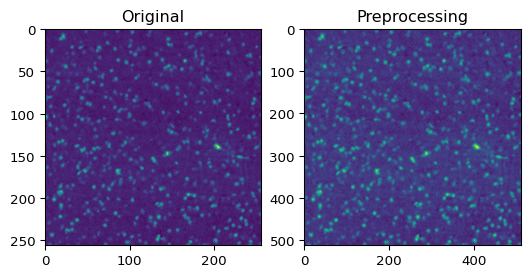

In [57]:
fig, axs = plt.subplots(1,2)

axs[0].imshow(img[0])
axs[0].set_title('Original')

axs[1].imshow(img_up[0])
axs[1].set_title('Preprocessing')

# (1) Apply each model to the target volume

In [18]:
# Segment annotated region from original img, to dec memory cost
img_ann = img[96:160, 96:160, 96:160]
print(f'Annotated area size: {img_ann.shape}')

# In original dataset, avg cell diameter is 5-8 voxels, so upsamping inc this to 10-16 voxels
img_up = preprocess_3D(img_ann)
print(f'(Upsampled) Annotated area size: {img_up.shape}')

Annotated area size: (64, 64, 64)
(Upsampled) Annotated area size: (128, 128, 128)


In [20]:
# Apply YOLO (img is upsampled and gamma corrected)
start = time.time()
outdir_slices = '/home/abenneck/misc_outputs/gt_data/slices_orig'
outdir_cube = '/home/abenneck/misc_outputs/gt_data/cube_orig'
apply_2D_yolo_to_slices(img, model_path, outdir_slices, verbose = False)
yolo_out = stitch_slices_into_cube(os.path.join(outdir_slices,'ax0'), os.path.join(outdir_slices,'ax1'), os.path.join(outdir_slices,'ax2'), outdir_cube)
yolo_out = np.load(os.path.join(outdir_cube,'i0000_j0000_k0000_d256_Ex_488_Em_525.npy'))
conf_thresh=1e-3
nms_thresh=0.3
yolo_nms = NMS(yolo_out, conf_thresh = conf_thresh, nms_thresh = nms_thresh)
print(f'Finished applying YOLO model in {time.time() - start:.2f}s')

# Apply Stardist
start = time.time()
stardist_labels, stardist_raw_outputs = star_model.predict_instances(img_up)
print(f'Finished applying StarDist model in {time.time() - start:.2f}s')

# Apply Cellpose
img_3ch = img_up[None] # Add a channel dimension since, CellPose requires the input image to have "at least 3 channels"
start = time.time()
masks_stitched, flows_stitched, _ = cell_model.eval(img_3ch, z_axis=1, channel_axis=0,
                                                  batch_size=32,
                                                  do_3D=False, stitch_threshold=0.5)
print(f'Finished applying CellPose model in {time.time() - start:.2f}s')

# Apply the Equivariance model
start = time.time()
outdir_slices = f'/home/abenneck/misc_outputs/gt_data/equiv_slices_perm'
outdir_cube = f'/home/abenneck/misc_outputs/gt_data/equiv_cube_perm'
apply_2D_equiv_to_slices(img, equiv_path, outdir_slices, verbose = False)
equi_out = stitch_slices_into_cube(os.path.join(outdir_slices,'ax0'), os.path.join(outdir_slices,'ax1'), os.path.join(outdir_slices,'ax2'), outdir_cube)
conf_thresh=1e-3
nms_thresh=0.3
equi_nms = NMS(equi_out, conf_thresh = conf_thresh, nms_thresh = nms_thresh)
print(f'Finished applying Equi model in {time.time() - start:.2f}s')   

Final shape - [64 64 64]
Total Cubes Shape: (1, 1, 1)
Starting cube (0,0,0) . . .
Edge? - True True True
Extent: [1.5,1021.5],[1.5,1021.5],[1.5,1021.5]
Extent_i:  [0,255],[0,255],[0,255]
Finished initializing global variables and data structures . . .
Finished combining detections along transverse view . . .
Finished combining detections along coronal view . . .
Finished combining detections along sagittal view . . .
(64, 64, 64, 8),(64, 64, 64, 8),(64, 64, 64, 8)
Finished cube (0,0,0) in 0.16s

................................................................97.85% of bboxes removed
Finished applying YOLO model in 76.59s
Finished applying StarDist model in 2.23s


_device.py (122): Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:848.)
100%|████████████████████████████████████████████████████████████████████████████████████████████| 127/127 [00:00<00:00, 2613.82it/s]


Finished applying CellPose model in 484.54s
Final shape - [64 64 64]
Total Cubes Shape: (1, 1, 1)
Starting cube (0,0,0) . . .
Edge? - True True True
Extent: [1.5,1021.5],[1.5,1021.5],[1.5,1021.5]
Extent_i:  [0,255],[0,255],[0,255]
Finished initializing global variables and data structures . . .
Finished combining detections along transverse view . . .
Finished combining detections along coronal view . . .
Finished combining detections along sagittal view . . .
(64, 64, 64, 8),(64, 64, 64, 8),(64, 64, 64, 8)
Finished cube (0,0,0) in 0.17s

................................................................95.84% of bboxes removed
Finished applying YOLO model in 226.35s


### (BROKEN) Visualize Data (Original img of s=256 + annotation of s=64)
- TODO?: In order to generate a plot in the units of the original img, the bb coords must be adjusted for the StarDist and CellPose outputs
- The NEXT plot is in units of the annotated + upsampled region, where the bb coords for GT and YOLO datasets are adjusted

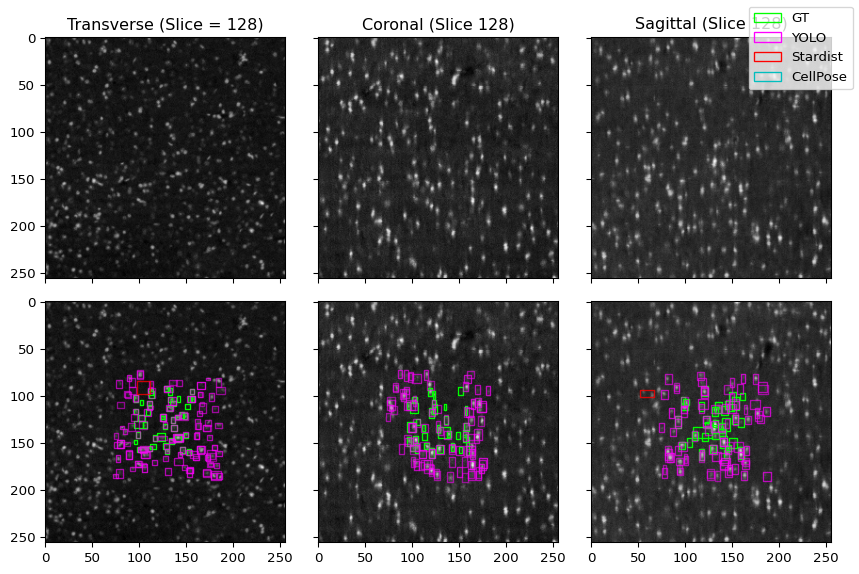

In [78]:
img_m0_idx = img.shape[0]//2
img_m1_idx = img.shape[1]//2
img_m2_idx = img.shape[2]//2

img0 = img[img_m0_idx,:,:]
img1 = img[:,img_m1_idx,:]
img2 = img[:,:,img_m2_idx]

lim = [96,160]

yolo_conf_thresh = 0.5
yolo_bb = yolo_output_to_bb_list(yolo_out)
star_bb = stardist_to_bb_list(stardist_raw_outputs, mode='3D')
cell_bb = cellpose_to_bb_list(masks_stitched)

# Each row will be a different angle, and each col will be (img, img+outputs)
fig, axs = plt.subplots(2,3,layout='tight', sharex=True, sharey=True)

# ==============================
# ===== Col 0 (Transverse) =====
# ==============================
# Original image
axs[0,0].imshow(img0, cmap='gray')
axs[0,0].set_title(f'Transverse (Slice = {img_m0_idx})')

# Original image
axs[1,0].imshow(img0, cmap='gray')

# GT bboxes
bb_plot_gt = bb_to_rec(bb_slice_filter(gt_bb, 0, img_m0_idx), pos = [4, 2, 5, 3], fc='none', ec='lime')
axs[1,0].add_collection(bb_plot_gt)

# YOLO bboxes
bb_yolo = bb_slice_filter(yolo_bb, 0, img_m0_idx)
scores = bb_yolo[:,-4]
scores[scores < yolo_conf_thresh] = 0.0
bb_plot_yolo = bb_to_rec(bb_yolo, pos = [4, 2, 5, 3], fc='none', ec='magenta', alpha=scores)
axs[1,0].add_collection(bb_plot_yolo)

# Stardist bboxes
bb_star = bb_slice_filter(star_bb, 0, img_m0_idx)
if len(bb_star) > 0:
    scores = bb_star[:,-1]
    bb_plot_star = bb_to_rec(bb_star, pos = [4, 2, 5, 3], fc='none', ec='red', alpha=scores)
    axs[1,0].add_collection(bb_plot_star)

# CellPose bboxes
bb_cell = bb_slice_filter(cell_bb, 0, img_m0_idx)
if len(bb_cell) > 0:
    bb_plot_cell = bb_to_rec(bb_cell, pos = [4, 2, 5, 3], fc='none', ec='c')
    axs[1,0].add_collection(bb_plot_cell)

# ===========================
# ===== Col 1 (Coronal) =====
# ===========================
# Original image
axs[0,1].imshow(img1, cmap='gray')
axs[0,1].set_title(f'Coronal (Slice {img_m1_idx})')

# Original image
axs[1,1].imshow(img1, cmap='gray')

# GT bboxes
bb_plot_gt = bb_to_rec(bb_slice_filter(gt_bb, 1, img_m1_idx), pos = [4, 0, 5, 1], fc='none', ec='lime')
axs[1,1].add_collection(bb_plot_gt)

# YOLO bboxes
bb_yolo = bb_slice_filter(yolo_bb, 1, img_m1_idx)
scores = bb_yolo[:,-4]
scores[scores < yolo_conf_thresh] = 0.0
bb_plot_yolo = bb_to_rec(bb_yolo, pos = [4, 0, 5, 1], fc='none', ec='magenta', alpha=scores)
axs[1,1].add_collection(bb_plot_yolo)

# Stardist bboxes
bb_star = bb_slice_filter(star_bb, 1, img_m1_idx)
if len(bb_star) > 0:
    scores = bb_star[:,-1]
    bb_plot_star = bb_to_rec(bb_star, pos = [4, 0, 5, 1], fc='none', ec='red', alpha=scores)
    axs[1,1].add_collection(bb_plot_star)

# CellPose bboxes
bb_cell = bb_slice_filter(cell_bb, 1, img_m1_idx)
if len(bb_cell) > 0:
    bb_plot_cell = bb_to_rec(bb_cell, pos = [4, 0, 5, 1], fc='none', ec='c')
    axs[1,1].add_collection(bb_plot_cell)


# ============================
# ===== Col 2 (Sagittal) =====
# ============================
# Original image
axs[0,2].imshow(img2, cmap='gray')
axs[0,2].set_title(f'Sagittal (Slice {img_m2_idx})')

# Original image
axs[1,2].imshow(img2, cmap='gray')

# GT bboxes
bb_plot_gt = bb_to_rec(bb_slice_filter(gt_bb, 2, img_m2_idx), pos = [2, 0, 3, 1], fc='none', ec='lime')
axs[1,2].add_collection(bb_plot_gt)

# YOLO bboxes
bb_yolo = bb_slice_filter(yolo_bb, 2, img_m2_idx)
scores = bb_yolo[:,-4]
scores[scores < yolo_conf_thresh] = 0.0
bb_plot_yolo = bb_to_rec(bb_yolo, pos = [2, 0, 3, 1], fc='none', ec='magenta', alpha=scores)
axs[1,2].add_collection(bb_plot_yolo)

# Stardist bboxes
bb_star = bb_slice_filter(star_bb, 2, img_m2_idx)
if len(bb_star) > 0:
    scores = bb_star[:,-1]
    bb_plot_star = bb_to_rec(bb_star, pos = [2, 0, 3, 1], fc='none', ec='red', alpha=scores)
    axs[1,2].add_collection(bb_plot_star)

# CellPose bboxes
bb_cell = bb_slice_filter(cell_bb, 2, img_m2_idx)
if len(bb_cell) > 0:
    bb_plot_cell = bb_to_rec(bb_cell, pos = [2, 0, 3, 1], fc='none', ec='c')
    axs[1,2].add_collection(bb_plot_cell)

# ========================
# ===== Whole Figure =====
# ========================

# Set same limits for every view
# for ax in axs:
#     for ax_i in ax:
#         ax_i.set_xlim(lim)
#         ax_i.set_ylim(lim)

# Generate a legend for the figure
legend_handles = [
    Patch(facecolor='none', edgecolor="lime", label="GT"),
    Patch(facecolor='none', edgecolor="magenta", label="YOLO"),
    Patch(facecolor='none', edgecolor="red", label="Stardist"),
    Patch(facecolor='none', edgecolor="c", label="CellPose"),
]
fig.legend(handles=legend_handles)

fig.set_size_inches(9,6)

### Visualize Data (Only the annotated area of s=64)

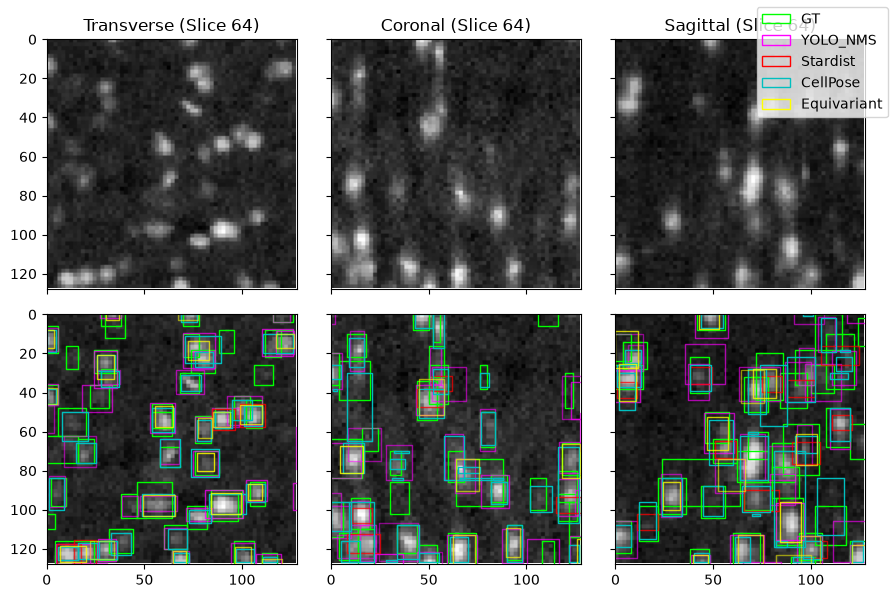

In [31]:
img_m0_idx = img_up.shape[0]//2
img_m1_idx = img_up.shape[1]//2
img_m2_idx = img_up.shape[2]//2

img0 = img_up[img_m0_idx,:,:]
img1 = img_up[:,img_m1_idx,:]
img2 = img_up[:,:,img_m2_idx]

lim = [0,128]

yolo_conf_thresh = 0.5
# yolo_bb = yolo_output_to_bb_list(yolo_out)
yolo_bb = yolo_output_to_bb_list(yolo_nms)
star_bb = stardist_to_bb_list(stardist_raw_outputs, mode='3D')
cell_bb = cellpose_to_bb_list(masks_stitched)
equi_bb = yolo_output_to_bb_list(equi_nms)

# Convert to relative units (YOLO and GT are in units of the original img, but Star and Cell are in units of the segmented, upsampled annotated region
gt_bb_adjusted = convert_bb_units(gt_bb)
yolo_bb_adjusted = convert_bb_units(yolo_bb)
equi_bb_adjusted = convert_bb_units(equi_bb)

# Each row will be a different angle, and each col will be (img, img+outputs)
fig, axs = plt.subplots(2,3,layout='tight', sharex=True, sharey=True)

# ==============================
# ===== Col 0 (Transverse) =====
# ==============================
# Original image
axs[0,0].imshow(img0, cmap='gray')
axs[0,0].set_title(f'Transverse (Slice {img_m0_idx})')

# Original image
axs[1,0].imshow(img0, cmap='gray')

# GT bboxes
bb_plot_gt = bb_to_rec(bb_slice_filter(gt_bb_adjusted, 0, img_m0_idx), pos = [4, 2, 5, 3], fc='none', ec='lime')
axs[1,0].add_collection(bb_plot_gt)

# YOLO bboxes
bb_yolo = bb_slice_filter(yolo_bb_adjusted, 0, img_m0_idx)
scores = bb_yolo[:,-4]
scores[scores < yolo_conf_thresh] = 0.0
bb_plot_yolo = bb_to_rec(bb_yolo, pos = [4, 2, 5, 3], fc='none', ec='magenta', alpha=scores)
axs[1,0].add_collection(bb_plot_yolo)

# Stardist bboxes
bb_star = bb_slice_filter(star_bb, 0, img_m0_idx)
if len(bb_star) > 0:
    scores = bb_star[:,-1]
    bb_plot_star = bb_to_rec(bb_star, pos = [4, 2, 5, 3], fc='none', ec='red', alpha=scores)
    axs[1,0].add_collection(bb_plot_star)

# CellPose bboxes
bb_cell = bb_slice_filter(cell_bb, 0, img_m0_idx)
if len(bb_cell) > 0:
    bb_plot_cell = bb_to_rec(bb_cell, pos = [4, 2, 5, 3], fc='none', ec='c')
    axs[1,0].add_collection(bb_plot_cell)

# Equivariant bboxes
bb_equi = bb_slice_filter(equi_bb_adjusted, 0, img_m0_idx)
scores = bb_equi[:,-4]
scores[scores < yolo_conf_thresh] = 0.0
bb_plot_equi = bb_to_rec(bb_equi, pos = [4, 2, 5, 3], fc='none', ec='yellow', alpha=scores)
axs[1,0].add_collection(bb_plot_equi)

# ===========================
# ===== Col 1 (Coronal) =====
# ===========================
# Original image
axs[0,1].imshow(img1, cmap='gray')
axs[0,1].set_title(f'Coronal (Slice {img_m1_idx})')

# Original image
axs[1,1].imshow(img1, cmap='gray')

# GT bboxes
bb_plot_gt = bb_to_rec(bb_slice_filter(gt_bb_adjusted, 1, img_m1_idx), pos = [4, 0, 5, 1], fc='none', ec='lime')
axs[1,1].add_collection(bb_plot_gt)

# YOLO bboxes
bb_yolo = bb_slice_filter(yolo_bb_adjusted, 1, img_m1_idx)
scores = bb_yolo[:,-4]
scores[scores < yolo_conf_thresh] = 0.0
bb_plot_yolo = bb_to_rec(bb_yolo, pos = [4, 0, 5, 1], fc='none', ec='magenta', alpha=scores)
axs[1,1].add_collection(bb_plot_yolo)

# Stardist bboxes
bb_star = bb_slice_filter(star_bb, 1, img_m1_idx)
if len(bb_star) > 0:
    scores = bb_star[:,-1]
    bb_plot_star = bb_to_rec(bb_star, pos = [4, 0, 5, 1], fc='none', ec='red', alpha=scores)
    axs[1,1].add_collection(bb_plot_star)

# CellPose bboxes
bb_cell = bb_slice_filter(cell_bb, 1, img_m1_idx)
if len(bb_cell) > 0:
    bb_plot_cell = bb_to_rec(bb_cell, pos = [4, 0, 5, 1], fc='none', ec='c')
    axs[1,1].add_collection(bb_plot_cell)

# Equivariant bboxes
bb_equi = bb_slice_filter(equi_bb_adjusted, 1, img_m1_idx)
scores = bb_equi[:,-4]
scores[scores < yolo_conf_thresh] = 0.0
bb_plot_equi = bb_to_rec(bb_equi, pos = [4, 0, 5, 1], fc='none', ec='yellow', alpha=scores)
axs[1,1].add_collection(bb_plot_equi)

# ============================
# ===== Col 2 (Sagittal) =====
# ============================
# Original image
axs[0,2].imshow(img2, cmap='gray')
axs[0,2].set_title(f'Sagittal (Slice {img_m2_idx})')

# Original image
axs[1,2].imshow(img2, cmap='gray')

# GT bboxes
bb_plot_gt = bb_to_rec(bb_slice_filter(gt_bb_adjusted, 2, img_m2_idx), pos = [2, 0, 3, 1], fc='none', ec='lime')
axs[1,2].add_collection(bb_plot_gt)

# YOLO bboxes
bb_yolo = bb_slice_filter(yolo_bb_adjusted, 2, img_m2_idx)
scores = bb_yolo[:,-4]
scores[scores < yolo_conf_thresh] = 0.0
bb_plot_yolo = bb_to_rec(bb_yolo, pos = [2, 0, 3, 1], fc='none', ec='magenta', alpha=scores)
axs[1,2].add_collection(bb_plot_yolo)

# Stardist bboxes
bb_star = bb_slice_filter(star_bb, 2, img_m2_idx)
if len(bb_star) > 0:
    scores = bb_star[:,-1]
    bb_plot_star = bb_to_rec(bb_star, pos = [2, 0, 3, 1], fc='none', ec='red', alpha=scores)
    axs[1,2].add_collection(bb_plot_star)

# CellPose bboxes
bb_cell = bb_slice_filter(cell_bb, 2, img_m2_idx)
if len(bb_cell) > 0:
    bb_plot_cell = bb_to_rec(bb_cell, pos = [2, 0, 3, 1], fc='none', ec='c')
    axs[1,2].add_collection(bb_plot_cell)

# Equivariant bboxes
bb_equi = bb_slice_filter(equi_bb_adjusted, 2, img_m2_idx)
scores = bb_equi[:,-4]
scores[scores < yolo_conf_thresh] = 0.0
bb_plot_equi = bb_to_rec(bb_equi, pos = [2, 0, 3, 1], fc='none', ec='yellow', alpha=scores)
axs[1,2].add_collection(bb_plot_equi)

# ========================
# ===== Whole Figure =====
# ========================

# Set same limits for every view
for ax in axs:
    for ax_i in ax:
        ax_i.set_xlim(lim)
        ax_i.set_ylim([lim[1],lim[0]])

# Generate a legend for the figure
legend_handles = [
    Patch(facecolor='none', edgecolor="lime", label="GT"),
    Patch(facecolor='none', edgecolor="magenta", label="YOLO_NMS"),
    Patch(facecolor='none', edgecolor="red", label="Stardist"),
    Patch(facecolor='none', edgecolor="c", label="CellPose"),
    Patch(facecolor='none', edgecolor="yellow", label="Equivariant"),
]

fig.legend(handles=legend_handles)

fig.set_size_inches(9,6)

### Plot all bb pruned during NMS

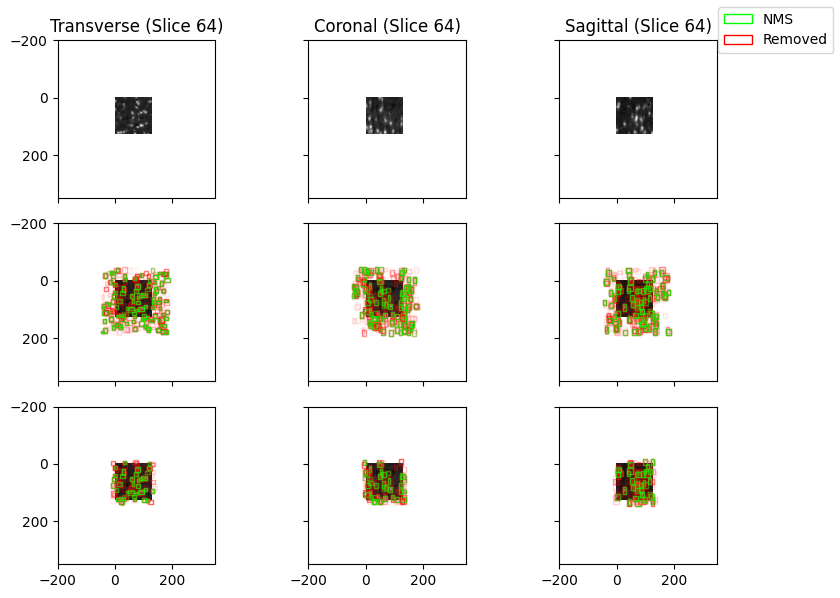

In [33]:
img_m0_idx = img_up.shape[0]//2
img_m1_idx = img_up.shape[1]//2
img_m2_idx = img_up.shape[2]//2

img0 = img_up[img_m0_idx,:,:]
img1 = img_up[:,img_m1_idx,:]
img2 = img_up[:,:,img_m2_idx]

# xlim = [0,128]
# ylim = [128,0]

# xlim = [96,160]
# ylim = [96,160]

xlim = [-200,350]
ylim = [350,-200]

# Convert YOLO outputs into lists of bboxes
yolo_bb = yolo_output_to_bb_list(yolo_out)
yolo_bb_nms = yolo_output_to_bb_list(yolo_nms)

# Convert to relative units (YOLO and GT are in units of the original img, but Star and Cell are in units of the segmented, upsampled annotated region
gt_bb_adjusted = convert_bb_units(gt_bb)
yolo_bb = convert_bb_units(yolo_bb)
yolo_bb_nms = convert_bb_units(yolo_bb_nms)

# Remove bb predictions outside of the annotated area
yolo_bb_trimmed = trim_bb(yolo_bb)
yolo_bb_nms_trimmed = trim_bb(yolo_bb_nms)


# Each row will be a different angle, and each col will be (img, img+outputs)
fig, axs = plt.subplots(3,3,layout='tight', sharex=True, sharey=True)

# ==============================
# ===== Col 0 (Transverse) =====
# ==============================
# Original image
axs[0,0].imshow(img0, cmap='gray')
axs[0,0].set_title(f'Transverse (Slice {img_m0_idx})')

# Original image
axs[1,0].imshow(img0, cmap='gray')

# GT bboxes
# bb_plot_gt = bb_to_rec(bb_slice_filter(gt_bb, 0, img_m0_idx), pos = [4, 2, 5, 3], fc='none', ec='lime')
# axs[1,0].add_collection(bb_plot_gt)

# YOLO bboxes (Orig)
bb_yolo = bb_slice_filter(yolo_bb, 0, img_m0_idx)
if len(bb_yolo) > 0:
    scores = bb_yolo[:,-4]
    bb_plot_yolo = bb_to_rec(bb_yolo, pos = [4, 2, 5, 3], fc='none', ec='red', alpha=scores)
    axs[1,0].add_collection(bb_plot_yolo)

bb_yolo_nms = bb_slice_filter(yolo_bb_nms, 0, img_m0_idx)
if len(bb_yolo_nms) > 0:
    scores = bb_yolo_nms[:,-4]
    bb_plot_yolo_nms = bb_to_rec(bb_yolo_nms, pos = [4, 2, 5, 3], fc='none', ec='lime', alpha=scores)
    axs[1,0].add_collection(bb_plot_yolo_nms)

# Original image
axs[2,0].imshow(img0, cmap='gray')

# YOLO bboxes (Orig)
bb_yolo_trimmed = bb_slice_filter(yolo_bb_trimmed, 0, img_m0_idx)
if len(bb_yolo_trimmed) > 0:
    scores = bb_yolo_trimmed[:,-4]
    bb_plot_yolo_trimmed = bb_to_rec(bb_yolo_trimmed, pos = [4, 2, 5, 3], fc='none', ec='red', alpha=scores)
    axs[2,0].add_collection(bb_plot_yolo_trimmed)

bb_yolo_nms_trimmed = bb_slice_filter(yolo_bb_nms_trimmed, 0, img_m0_idx)
if len(bb_yolo_nms_trimmed) > 0:
    scores = bb_yolo_nms_trimmed[:,-4]
    bb_plot_yolo_nms_trimmed = bb_to_rec(bb_yolo_nms_trimmed, pos = [4, 2, 5, 3], fc='none', ec='lime', alpha=scores)
    axs[2,0].add_collection(bb_plot_yolo_nms_trimmed)

# ===========================
# ===== Col 1 (Coronal) =====
# ===========================
# Original image
axs[0,1].imshow(img1, cmap='gray')
axs[0,1].set_title(f'Coronal (Slice {img_m1_idx})')

# Original image
axs[1,1].imshow(img1, cmap='gray')

# GT bboxes
# bb_plot_gt = bb_to_rec(bb_slice_filter(gt_bb, 1, img_m1_idx), pos = [4, 0, 5, 1], fc='none', ec='lime')
# axs[1,1].add_collection(bb_plot_gt)

# YOLO bboxes
bb_yolo = bb_slice_filter(yolo_bb, 1, img_m1_idx)
if len(bb_yolo) > 0:
    scores = bb_yolo[:,-4]
    bb_plot_yolo = bb_to_rec(bb_yolo, pos = [4, 0, 5, 1], fc='none', ec='red', alpha=scores)
    axs[1,1].add_collection(bb_plot_yolo)

bb_yolo_nms = bb_slice_filter(yolo_bb_nms, 1, img_m1_idx)
if len(bb_yolo_nms) > 0:
    scores = bb_yolo_nms[:,-4]
    bb_plot_yolo_nms = bb_to_rec(bb_yolo_nms, pos = [4, 0, 5, 1], fc='none', ec='lime', alpha=scores)
    axs[1,1].add_collection(bb_plot_yolo_nms)

# Original image
axs[2,1].imshow(img1, cmap='gray')

# YOLO bboxes
bb_yolo_trimmed = bb_slice_filter(yolo_bb_trimmed, 1, img_m1_idx)
if len(bb_yolo_trimmed) > 0:
    scores = bb_yolo_trimmed[:,-4]
    bb_plot_yolo_trimmed = bb_to_rec(bb_yolo_trimmed, pos = [4, 0, 5, 1], fc='none', ec='red', alpha=scores)
    axs[2,1].add_collection(bb_plot_yolo_trimmed)

bb_yolo_nms_trimmed = bb_slice_filter(yolo_bb_nms_trimmed, 1, img_m1_idx)
if len(bb_yolo_nms_trimmed) > 0:
    scores = bb_yolo_nms_trimmed[:,-4]
    bb_plot_yolo_nms_trimmed = bb_to_rec(bb_yolo_nms_trimmed, pos = [4, 0, 5, 1], fc='none', ec='lime', alpha=scores)
    axs[2,1].add_collection(bb_plot_yolo_nms_trimmed)


# ============================
# ===== Col 2 (Sagittal) =====
# ============================
# Original image
axs[0,2].imshow(img2, cmap='gray')
axs[0,2].set_title(f'Sagittal (Slice {img_m2_idx})')

# Original image
axs[1,2].imshow(img2, cmap='gray')

# GT bboxes
# bb_plot_gt = bb_to_rec(bb_slice_filter(gt_bb, 2, img_m2_idx), pos = [2, 0, 3, 1], fc='none', ec='lime')
# axs[1,2].add_collection(bb_plot_gt)

# YOLO bboxes
bb_yolo = bb_slice_filter(yolo_bb, 2, img_m2_idx)
if len(bb_yolo) > 0:
    scores = bb_yolo[:,-4]
    bb_plot_yolo = bb_to_rec(bb_yolo, pos = [2, 0, 3, 1], fc='none', ec='red', alpha=scores)
    axs[1,2].add_collection(bb_plot_yolo)

bb_yolo_nms = bb_slice_filter(yolo_bb_nms, 2, img_m2_idx)
if len(bb_yolo_nms) > 0:
    scores = bb_yolo_nms[:,-4]
    bb_plot_yolo_nms = bb_to_rec(bb_yolo_nms, pos = [2, 0, 3, 1], fc='none', ec='lime', alpha=scores)
    axs[1,2].add_collection(bb_plot_yolo_nms)

# Original image
axs[2,2].imshow(img2, cmap='gray')

# YOLO bboxes (Trimmed)
bb_yolo_trimmed = bb_slice_filter(yolo_bb_trimmed, 2, img_m2_idx)
if len(bb_yolo_trimmed) > 0:
    scores = bb_yolo_trimmed[:,-4]
    bb_plot_yolo_trimmed = bb_to_rec(bb_yolo_trimmed, pos = [2, 0, 3, 1], fc='none', ec='red', alpha=scores)
    axs[2,2].add_collection(bb_plot_yolo_trimmed)

bb_yolo_nms_trimmed = bb_slice_filter(yolo_bb_nms_trimmed, 2, img_m2_idx)
if len(bb_yolo_nms_trimmed) > 0:
    scores = bb_yolo_nms_trimmed[:,-4]
    bb_plot_yolo_nms_trimmed = bb_to_rec(bb_yolo_nms_trimmed, pos = [2, 0, 3, 1], fc='none', ec='lime', alpha=scores)
    axs[2,2].add_collection(bb_plot_yolo_nms_trimmed)


# ========================
# ===== Whole Figure =====
# ========================

# Set same limits for every view
for ax in axs:
    for ax_i in ax:
        ax_i.set_xlim(xlim)
        ax_i.set_ylim(ylim)

# Generate a legend for the figure
legend_handles = [
    Patch(facecolor='none', edgecolor="lime", label="NMS"),
    Patch(facecolor='none', edgecolor="red", label="Removed"),
]
fig.legend(handles=legend_handles)

fig.set_size_inches(9,6)

# (2) Compute AP, generate plots, and compare performance

### Compute AP (IOU = 0.5) for each model

In [83]:
# NOTE: Each element of the 'performance' object contains a list of values defined as follows:
# [idx, best_gt_iou_idx, pred_conf, best_gt_iou, TP, FP, total_TP, total_FP, precision, recall]

iou_thresh = 0.1

# Convert to relative units (YOLO and GT are in units of the original img, but Star and Cell are in units of the segmented, upsampled annotated region
gt_bb_adjusted = convert_bb_units(gt_bb)

# YOLO
yolo_bb = yolo_output_to_bb_list(yolo_out)
yolo_bb_adjusted = convert_bb_units(yolo_bb)
yolo_bb_final = trim_bb(yolo_bb_adjusted)
yolo_bb_final = remove_low_conf_bb(yolo_bb_final)
AP_yolo, perf_yolo = get_AP(gt_bb_adjusted, yolo_bb_final, iou_thresh = iou_thresh, verbose = True)

yolo_bb_nms = yolo_output_to_bb_list(yolo_nms)
yolo_bb_nms_adjusted = convert_bb_units(yolo_bb_nms)
yolo_bb_nms_final = trim_bb(yolo_bb_nms_adjusted)
yolo_bb_nms_final = remove_low_conf_bb(yolo_bb_nms_final)
AP_yolo_nms, perf_yolo_nms = get_AP(gt_bb_adjusted, yolo_bb_nms_final, iou_thresh = iou_thresh, verbose = True)

# Stardist
star_bb = stardist_to_bb_list(stardist_raw_outputs, mode = '3D')
AP_star, perf_star = get_AP(gt_bb_adjusted, star_bb, conf_idx = -1, iou_thresh = iou_thresh, verbose = True)

# Cellpose
cell_bb = cellpose_to_bb_list(masks_stitched)
AP_cell, perf_cell = get_AP(gt_bb_adjusted, cell_bb, conf_idx = -1, iou_thresh = iou_thresh, verbose = True)

print(f'AP_yolo: {AP_yolo:.2f} vs AP_yolo (NMS): {AP_yolo_nms:.2f} vs AP_star: {AP_star:.2f} vs AP_cell: {AP_cell:.2f} ')

AP_yolo: 0.75 vs AP_yolo (NMS): 0.77 vs AP_star: 0.27 vs AP_cell: 0.43 


In [84]:
# num_yolo = len(yolo_bb_final)
# print(num_yolo)

# num_yolo_nms = len(np.where(yolo_bb_nms[:,-4] > 0)[0])
# print(num_yolo_nms)

print(f'GT: {len(gt_bb_adjusted)} total cells')
print()
print(f'{"Dataset":<10}: {"AP":<6} | # detections | total TP | total FP ')
print(f'{"YOLO":<10}: {AP_yolo:.4f} | {len(yolo_bb_final)} {"|":>9} {perf_yolo[-1,-4].astype(int)} {"|":>6} {perf_yolo[-1,-3].astype(int)}')
print(f'{"YOLO (NMS)":<10}: {AP_yolo_nms:.4f} | {len(yolo_bb_nms_final)} {"|":>9} {perf_yolo_nms[-1,-4].astype(int)} {"|":>6} {perf_yolo_nms[-1,-3].astype(int)}')
print(f'{"StarDist":<10}: {AP_star:.4f} | {len(star_bb)} {"|":>11} {perf_star[-1,-4].astype(int)} {"|":>7} {perf_star[-1,-3].astype(int)}')
print(f'{"CellPose":<10}: {AP_cell:.4f} | {len(cell_bb)} {"|":>10} {perf_cell[-1,-4].astype(int)} {"|":>6} {perf_cell[-1,-3].astype(int)}')

GT: 276 total cells

Dataset   : AP     | # detections | total TP | total FP 
YOLO      : 0.7458 | 5681         | 275      | 5406
YOLO (NMS): 0.7712 | 1371         | 268      | 1103
StarDist  : 0.2664 | 76           | 75       | 1
CellPose  : 0.4295 | 379          | 222      | 157


In [85]:
# Final (P, R, TP, FP)
print(perf_yolo_nms[-1,-2], perf_yolo_nms[-1,-1], perf_yolo_nms[-1,-4], perf_yolo_nms[-1,-3])

0.19547775346462437 0.9710144927536232 268.0 1103.0


### Plot results

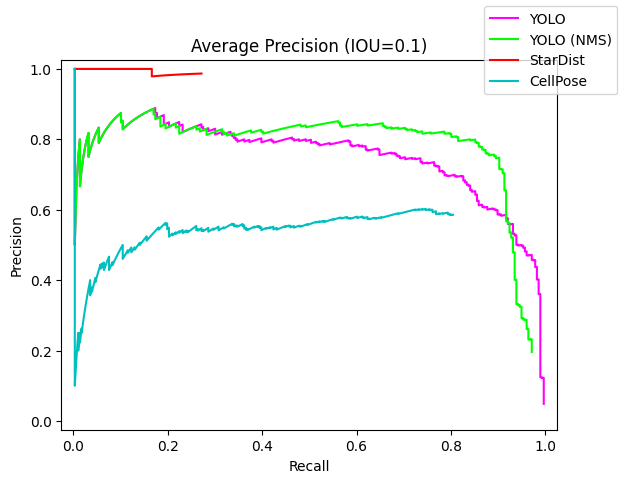

In [76]:
fig, ax = plt.subplots()
ax.plot(perf_yolo[:,-1], perf_yolo[:,-2], color='magenta', label='YOLO')
ax.plot(perf_yolo_nms[:,-1], perf_yolo_nms[:,-2], color='lime', label='YOLO (NMS)')
ax.plot(perf_star[:,-1], perf_star[:,-2], color='red', label='StarDist')
ax.plot(perf_cell[:,-1], perf_cell[:,-2], color='c', label='CellPose')

ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title(f'Average Precision (IOU={iou_thresh})')
ax.set_xlim([-0.025,1.025])
ax.set_ylim([-0.025,1.025])

_ = fig.legend()

# for bb in performance:
#     # If the bbox was a TP, plot it
#     if bb[3] == 1:
#         # print('Added point')
#         ax.scatter(bb[-1], bb[-2], color = 'green', linewidth = 0.5)


### Compute mAP (0.5:0.05:1.0) for each model

In [ ]:
# all_mAP = []
# for all_bb in [yolo_bb, star_bb, cell_bb]:
#     rolling_AP = 0
#     for iou in np.arange(0.5,1,0.05):
#         AP, performance = get_AP(gt_bb, all_bb, iou_thresh = iou, verbose = False)
#         rolling_AP += AP
#     mAP = rolling_AP / 10
#     all_mAP.append(mAP)

# (4) Use GridSearch CV to find the best (nms_thresh, conf_thresh) combination

In [113]:
# Define iou_thresh and compute AP for YOLO output WITHOUT NMS
iou_thresh = 0.3

outdir_cube = '/ifshome/abenneck/docs_public/misc_outputs/gt_data/cube'
yolo_out = np.load(os.path.join(outdir_cube,'i0000_j0000_k0000_d256_Ex_488_Em_525.npy'))
yolo_bb = yolo_output_to_bb_list(yolo_out)
yolo_bb_adjusted = convert_bb_units(yolo_bb)
yolo_bb_final = trim_bb(yolo_bb_adjusted)
yolo_bb_final = remove_low_conf_bb(yolo_bb_final)
AP_yolo, perf_yolo = get_AP(gt_bb_adjusted, yolo_bb_final, iou_thresh = iou_thresh, verbose = True)
print(AP_yolo)

0.580636528796262


In [134]:
all_conf = np.arange(0.001,0.02,0.001)
all_nms  = np.arange(0,1,0.1)
all_AP = np.zeros((len(all_conf), len(all_nms)))

for i, conf_thresh in enumerate(all_conf):
    for j, nms_thresh in enumerate(all_nms):

        print(f'Starting (conf, nms) = ({conf_thresh}, {nms_thresh})')
                  
        start = time.time()

        # Apply NMS to the single cube
        yolo_nms = NMS(yolo_out, conf_thresh = conf_thresh, nms_thresh = nms_thresh)
 
        # Convert the output from an array to a list
        yolo_bb_nms = yolo_output_to_bb_list(yolo_nms)

        # NOTE: I pushed the entire GT image of size 256 through the YOLO pipeline, but only the middle cube of size 64 was annotated
        #       So the units of the yolo output need to be converted into units relative to the annotated region.
        #       Also, the predictions outside of the annotated zone must be trimmed since there are no GT to compare against
        
        # Convert output units, so they are relative to the annotated region, with origin in the upper left corner
        yolo_bb_nms_adjusted = convert_bb_units(yolo_bb_nms)

        # Trim off predictions located outside of the annotated region
        yolo_bb_nms_final = trim_bb(yolo_bb_nms_adjusted)

        # Remove all bboxes with a confidence of 0
        yolo_bb_nms_final = remove_low_conf_bb(yolo_bb_nms_final)

        # Compute AP for the current (conf_thresh, nms_thresh) pair
        AP_yolo_nms, perf_yolo_nms = get_AP(gt_bb_adjusted, yolo_bb_nms_final, iou_thresh = iou_thresh, verbose = True)

        all_AP[i,j] = AP_yolo_nms

        print(f'Finished NMS in {time.time() - start:.2f}s')




Starting (conf, nms) = (0.001, 0.0)
................................................................99.99% of bboxes removed
Finished NMS in 3.13s
Starting (conf, nms) = (0.001, 0.1)
................................................................99.36% of bboxes removed
Finished NMS in 2.65s
Starting (conf, nms) = (0.001, 0.2)
................................................................98.86% of bboxes removed
Finished NMS in 3.64s
Starting (conf, nms) = (0.001, 0.30000000000000004)
................................................................97.85% of bboxes removed
Finished NMS in 3.91s
Starting (conf, nms) = (0.001, 0.4)
................................................................96.57% of bboxes removed
Finished NMS in 5.83s
Starting (conf, nms) = (0.001, 0.5)
................................................................95.53% of bboxes removed
Finished NMS in 6.21s
Starting (conf, nms) = (0.001, 0.6000000000000001)
...................................................

In [135]:
import pandas as pd

df = pd.DataFrame(all_AP, columns = all_nms, index = all_conf)
df

,0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9
0.001,0.004106,0.493348,0.537084,0.574302,0.597034,0.591867,0.583303,0.580718,0.580637,0.580637
0.002,0.004106,0.493348,0.537084,0.574302,0.597034,0.591867,0.583303,0.580718,0.580637,0.580637
0.003,0.004106,0.493348,0.537084,0.574302,0.597034,0.591867,0.583303,0.580718,0.580637,0.580637
0.004,0.004106,0.493348,0.537084,0.573609,0.597034,0.591867,0.583303,0.580718,0.580637,0.580637
0.005,0.004106,0.493348,0.537084,0.573609,0.597034,0.591867,0.583303,0.580718,0.580637,0.580637
0.006,0.004106,0.493348,0.537084,0.573609,0.597034,0.591867,0.583303,0.580718,0.580637,0.580637
0.007,0.004106,0.493348,0.537084,0.573609,0.597034,0.591867,0.583303,0.580718,0.580637,0.580637
0.008,0.004106,0.493348,0.537084,0.573609,0.596504,0.591461,0.582943,0.580370,0.580291,0.580291
0.009,0.004106,0.493348,0.537084,0.573609,0.596504,0.591461,0.582943,0.580370,0.580291,0.580291
0.010,0.004106,0.493348,0.537084,0.572738,0.596504,0.591461,0.582943,0.580370,0.580291,0.580291


# (5) Compare model performance on different permutations of the GT data

### Load all the models + reload images if necessary

In [6]:
# Set device for all PyTorch models
# torch.set_default_device("cuda:0")
torch.set_default_device("cpu")

# Load the YOLO model
model_path = '/home/abenneck/mounts/bmaproot/nafs/shattuck/RodentToolsData/ZW-DT-1-P56-1/yolo_saved_weights/modelsave_bright_on_dark.pt'
net = Net()
net.load_state_dict(torch.load(model_path))
B = net.B
stride = net.stride
print('Successfully loaded YOLO model . . .')

# Disable CUDA (Needed to force StarDist3D to initialize on the cpu, since it uses keras NOT pytorch)
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

# Load the Stardist model (Built on Keras)
star_model = StarDist3D.from_pretrained('3D_demo')
print('Successfully loaded StarDist model . . .')

# Load the Cellpose model (ALL pretrained model weights: ["cpsam_v2" (DEFAULT), "cpdino", "cpdino-vitb", "cpsam"])
cell_model = models.CellposeModel(gpu=False, pretrained_model="cpsam_v2")
print('Successfully loaded CellPose model . . .')

# Load the target volume
indir = os.path.join(os.path.split(os.getcwd())[0], 'inputs')
img_path = os.path.join(indir, 'cube_i0002_j0005_k0003.nii.gz')
img = nib.load(img_path)
img = img.get_fdata()
print('Successfully loaded target volume . . .')

# Load the GT annotation + convert to list(bbox)
mask_path = os.path.join(indir, 'mask64_i0002_j0005_k0003_annotated.nii.gz')
mask_nib = nib.load(mask_path)
mask = mask_nib.get_fdata()
gt_bb = gt_mask_to_bb_list(mask) # Convert integer-valued img into a list of bboxes
print(f'Successfully loaded GT annotations ({len(gt_bb)} total cells) . . .')

Successfully loaded YOLO model . . .
Found model '3D_demo' for 'StarDist3D'.


2026-11-03 15:15:07.011741: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected
2026-11-03 15:15:07.011759: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:167] env: CUDA_VISIBLE_DEVICES="-1"
2026-11-03 15:15:07.011762: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:170] CUDA_VISIBLE_DEVICES is set to -1 - this hides all GPUs from CUDA
2026-11-03 15:15:07.011764: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:178] verbose logging is disabled. Rerun with verbose logging (usually --v=1 or --vmodule=cuda_diagnostics=1) to get more diagnostic output from this module
2026-11-03 15:15:07.011766: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:183] retrieving CUDA diagnostic information for host: alienware
2026-11-03 15:15:07.011768: I external/local_xla/xla/stream_executor/cuda/cud

Loading network weights from 'weights_best.h5'.
Loading thresholds from 'thresholds.json'.
Using default values: prob_thresh=0.707933, nms_thresh=0.3.
Successfully loaded StarDist model . . .
Successfully loaded CellPose model . . .
Successfully loaded target volume . . .
Successfully loaded GT annotations (276 total cells) . . .


### Permute input image + GT annotations

In [7]:
flips = [True, False, False]
perm = 1

img_perm = img.copy()
img_perm = permute_vol(img_perm, flips, perm)

gt_bb = gt_mask_to_bb_list(mask)

mask_perm = mask.copy()
mask_perm = permute_vol(mask_perm, flips, perm)
gt_bb_perm = gt_mask_to_bb_list(mask_perm)

# Segment annotated region from original img, to dec memory cost
img_ann = img_perm[96:160, 96:160, 96:160]
print(f'Annotated area size: {img_ann.shape}')

# In original dataset, avg cell diameter is 5-8 voxels, so upsamping inc this to 10-16 voxels
img_up = preprocess_3D(img_ann)
print(f'(Upsampled) Annotated area size: {img_up.shape}')

Annotated area size: (64, 64, 64)
(Upsampled) Annotated area size: (128, 128, 128)


### Apply each model to permuted data

In [41]:
# Apply YOLO (img is upsampled and gamma corrected)
start = time.time()
outdir_slices = '/home/abenneck/misc_outputs/gt_data/slices_orig'
outdir_cube = '/home/abenneck/misc_outputs/gt_data/cube_orig'
apply_2D_yolo_to_slices(img_perm, model_path, outdir_slices, verbose = False)
# apply_2D_yolo_to_slices(img_ann, model_path, outdir_slices, verbose = False)
yolo_out = stitch_slices_into_cube(os.path.join(outdir_slices,'ax0'), os.path.join(outdir_slices,'ax1'), os.path.join(outdir_slices,'ax2'), outdir_cube)
# yolo_out = np.load(os.path.join(outdir_cube,'i0000_j0000_k0000_d256_Ex_488_Em_525.npy'))
conf_thresh = 1e-3
nms_thresh = 0.3
yolo_nms = NMS(yolo_out, conf_thresh = conf_thresh, nms_thresh = nms_thresh)
print(f'Finished applying YOLO model in {time.time() - start:.2f}s')

# Apply Stardist
start = time.time()
stardist_labels, stardist_raw_outputs = star_model.predict_instances(img_up)
print(f'Finished applying StarDist model in {time.time() - start:.2f}s')

# Apply Cellpose
img_3ch = img_up[None] # Add a channel dimension since, CellPose requires the input image to have "at least 3 channels"
start = time.time()
masks_stitched, flows_stitched, _ = cell_model.eval(img_3ch, z_axis=1, channel_axis=0,
                                                  batch_size=32,
                                                  do_3D=False, stitch_threshold=0.5)
print(f'Finished applying CellPose model in {time.time() - start:.2f}s')

_device.py (122): To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).


Total Cubes Shape: (1, 1, 1)
Starting cube (0,0,0) . . .
Edge? - True True True
Extent: [1.5,1021.5],[1.5,1021.5],[1.5,1021.5]
Extent_i:  [0,255],[0,255],[0,255]
Finished initializing global variables and data structures . . .
Finished combining detections along transverse view . . .
Finished combining detections along coronal view . . .
Finished combining detections along sagittal view . . .
(64, 64, 64, 8),(64, 64, 64, 8),(64, 64, 64, 8)
Finished cube (0,0,0) in 0.17s

................................................................97.84% of bboxes removed
Finished applying YOLO model in 80.13s
Finished applying StarDist model in 2.21s


_device.py (122): Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:848.)
100%|████████████████████████████████████████████████████████████████████████████████████████████| 127/127 [00:00<00:00, 2885.88it/s]

Finished applying CellPose model in 467.59s


In [42]:
# NOTE: Each element of the 'performance' object contains a list of values defined as follows:
# [idx, best_gt_iou_idx, pred_conf, best_gt_iou, TP, FP, total_TP, total_FP, precision, recall]

iou_thresh = 0.1

# Convert to relative units (YOLO and GT are in units of the original img, but Star and Cell are in units of the segmented, upsampled annotated region
gt_bb_adjusted = convert_bb_units(gt_bb_perm)

# YOLO
yolo_bb = yolo_output_to_bb_list(yolo_out)
yolo_bb_adjusted = convert_bb_units(yolo_bb)
yolo_bb_final = trim_bb(yolo_bb_adjusted)
yolo_bb_final = remove_low_conf_bb(yolo_bb_final)
AP_yolo, perf_yolo, bb_pred_yolo = get_AP(gt_bb_adjusted, yolo_bb_final, iou_thresh = iou_thresh, verbose = True)

yolo_bb_nms = yolo_output_to_bb_list(yolo_nms)
yolo_bb_nms_adjusted = convert_bb_units(yolo_bb_nms)
yolo_bb_nms_final = trim_bb(yolo_bb_nms_adjusted)
yolo_bb_nms_final = remove_low_conf_bb(yolo_bb_nms_final)
AP_yolo_nms, perf_yolo_nms, bb_pred_yolo_nms = get_AP(gt_bb_adjusted, yolo_bb_nms_final, iou_thresh = iou_thresh, verbose = True)

# Stardist
star_bb = stardist_to_bb_list(stardist_raw_outputs, mode = '3D')
AP_star, perf_star, bb_pred_star = get_AP(gt_bb_adjusted, star_bb, conf_idx = -1, iou_thresh = iou_thresh, verbose = True)

# Cellpose
cell_bb = cellpose_to_bb_list(masks_stitched)
AP_cell, perf_cell, bb_pred_cell = get_AP(gt_bb_adjusted, cell_bb, conf_idx = -1, iou_thresh = iou_thresh, verbose = True)

print(f'AP_yolo: {AP_yolo:.2f} vs AP_yolo (NMS): {AP_yolo_nms:.2f} vs AP_star: {AP_star:.2f} vs AP_cell: {AP_cell:.2f} ')
# print(f'AP_yolo: {AP_yolo:.2f} vs AP_yolo (NMS): {AP_yolo_nms:.2f}')

AP_yolo: 0.76 vs AP_yolo (NMS): 0.78 vs AP_star: 0.27 vs AP_cell: 0.41 


In [43]:
# Sort all detections by GT cell ID number
cell_idx = 1
inds = np.argsort(perf_yolo_nms[..., cell_idx], axis = 0) # Get indeces of predictions, sorted by cell ID number

perf_yolo_nms_sorted = np.flip(perf_yolo_nms[inds], axis = 0)
bb_pred_yolo_nms_sorted = np.flip(bb_pred_yolo_nms[inds], axis = 0)

### Initialize the pd.df for storing all bbox info

In [12]:
n_perm = 8
n_flip = 6

columns = ["Cell ID", "GT"]
for i in range(n_perm*n_flip):
    columns.append(f"Perm {i}")
for i in range(n_perm*n_flip):
    columns.append(f"Orig {i}")

# NOTE: First elem in each list is the row label
# NOTE: Second elem in each list corresponds to the GT dataset. Each elem after corresponds to the transformations applied
row_flip0 = ["Flip_ax0", False]
for i in range(n_flip*2):
    row_flip0.append([False, True, True, True, True, False, False, False])
row_flip0 = [b for x in row_flip0 for b in (x if isinstance(x, list) else [x])]

row_flip1 = ["Flip_ax1", False]
for i in range(n_flip*2):
    row_flip1.append([False, False, True, False, True, True, True, False])
row_flip1 = [b for x in row_flip1 for b in (x if isinstance(x, list) else [x])]

row_flip2 = ["Flip_ax2", False]
for i in range(n_flip*2):
    row_flip2.append([False, False, False, True, True, False, True, True])
row_flip2 = [b for x in row_flip2 for b in (x if isinstance(x, list) else [x])]

row_order = ["Order", "012"]
all_orders = ["012", "021", "102", "120", "201", "210"]
for j in range(2):
    for order in all_orders:
        for i in range(n_perm):
            row_order.append(order)

# Initialize the DataFrame
df = pd.DataFrame([row_flip0, row_flip1, row_flip2, row_order], columns=columns)

# Add a row for every GT cell
gt_bb_adjusted = convert_bb_units(gt_bb)
cell_labels = [int(row[-1]) for row in gt_bb_adjusted]
for label in cell_labels:
    df.loc[len(df)] = [f'{label:.0f}'] + [np.nan for i in range(49+48)]

# Add the GT bbox info to each row
add_bbox_info(df, "GT", gt_bb_adjusted)

# Change dtype of each column to object
for col in df.columns:
    df[col] = df[col].astype(object)


# Initialize all df's
if True:
    yolo_df_path = '/home/abenneck/misc_outputs/gt_data/permutation_experiment/yolo_perm_exp.csv'
    df_yolo = df.to_csv(yolo_df_path, index = False)
    
    star_df_path = '/home/abenneck/misc_outputs/gt_data/permutation_experiment/star_perm_exp.csv'
    df_star = df.to_csv(star_df_path, index = False)
    
    cell_df_path = '/home/abenneck/misc_outputs/gt_data/permutation_experiment/cell_perm_exp.csv'
    df_cell = df.to_csv(cell_df_path, index = False)
    
    equiv_df_path = '/home/abenneck/misc_outputs/gt_data/permutation_experiment/equiv_perm_exp.csv'
    df_equiv = df.to_csv(equiv_df_path, index = False)

df.head(10)

,Cell ID,GT,Perm 0,Perm 1,Perm 2,Perm 3,Perm 4,Perm 5,Perm 6,Perm 7,...,Orig 38,Orig 39,Orig 40,Orig 41,Orig 42,Orig 43,Orig 44,Orig 45,Orig 46,Orig 47
0,Flip_ax0,False,False,True,True,True,True,False,False,False,...,False,False,False,True,True,True,True,False,False,False
1,Flip_ax1,False,False,False,True,False,True,True,True,False,...,True,False,False,False,True,False,True,True,True,False
2,Flip_ax2,False,False,False,False,True,True,False,True,True,...,True,True,False,False,False,True,True,False,True,True
3,Order,012,012,012,012,012,012,012,012,012,...,201,201,210,210,210,210,210,210,210,210
4,2,"[36, 52, 94, 106, -2, 4]",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,3,"[34, 52, 74, 84, -2, 6]",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,4,"[20, 36, 56, 68, -2, 4]",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,5,"[64, 76, 102, 110, -2, 4]",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,6,"[64, 84, 62, 76, -2, 16]",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,7,"[94, 108, 88, 100, -2, 2]",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Add bboxes from Permutation N to the relevant df

In [103]:
flips = [True, False, False]
perm = 1

add_bbox_info(df, "Orig 9", bb_pred_yolo_nms_sorted, pred_labels)

bb_new = reverse_perm(bb_pred_yolo_nms_sorted, flips=flips, perm=perm)
add_bbox_info(df, "Perm 9", bb_new, pred_labels)


# (6) Wrap the permutation experiment in one big loop (over 48 permutations)

### Load all of the models + Define relevant paths

In [13]:
# Set device for all PyTorch models
# torch.set_default_device("cuda:0")
torch.set_default_device("cpu")

# Load the YOLO model
model_path = '/home/abenneck/mounts/bmaproot/nafs/shattuck/RodentToolsData/ZW-DT-1-P56-1/yolo_saved_weights/modelsave_bright_on_dark.pt'
net = Net()
net.load_state_dict(torch.load(model_path))
B = net.B
stride = net.stride
print('Successfully loaded YOLO model . . .')

# Disable CUDA (Needed to force StarDist3D to initialize on the cpu, since it uses keras NOT pytorch)
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

# Load the Stardist model (Built on Keras)
star_model = StarDist3D.from_pretrained('3D_demo')
print('Successfully loaded StarDist model . . .')

# Load the Cellpose model (ALL pretrained model weights: ["cpsam_v2" (DEFAULT), "cpdino", "cpdino-vitb", "cpsam"])
cell_model = models.CellposeModel(gpu=False, pretrained_model="cpsam_v2")
print('Successfully loaded CellPose model . . .')

# Load the equivariance model
equiv_path = '/home/abenneck/equivariance_model/training_outputs/eq_weights.pt'
equiv_model = mk.EqNet()
equiv_model.load_state_dict(torch.load(equiv_path))
print('Successfully loaded Equivariant model . . .')

# Load the target volume
indir = os.path.join(os.path.split(os.getcwd())[0], 'inputs')
img_path = os.path.join(indir, 'cube_i0002_j0005_k0003.nii.gz')
img = nib.load(img_path)
img = img.get_fdata()
print('Successfully loaded target volume . . .')

# Load the GT annotation + convert to list(bbox)
mask_path = os.path.join(indir, 'mask64_i0002_j0005_k0003_annotated.nii.gz')
mask_nib = nib.load(mask_path)
mask = mask_nib.get_fdata()
gt_bb = gt_mask_to_bb_list(mask) # Convert integer-valued img into a list of bboxes
print(f'Successfully loaded GT annotations ({len(gt_bb)} total cells) . . .')

# csv files which will store each model's outputs across every experiment
yolo_df_path = '/home/abenneck/misc_outputs/gt_data/permutation_experiment/yolo_perm_exp.csv'
df_yolo = pd.read_csv(yolo_df_path)

star_df_path = '/home/abenneck/misc_outputs/gt_data/permutation_experiment/star_perm_exp.csv'
df_star = pd.read_csv(star_df_path)

cell_df_path = '/home/abenneck/misc_outputs/gt_data/permutation_experiment/cell_perm_exp.csv'
df_cell = pd.read_csv(cell_df_path)

equi_df_path = '/home/abenneck/misc_outputs/gt_data/permutation_experiment/equiv_perm_exp.csv'
df_equi = pd.read_csv(equiv_df_path)

In [19]:
all_perm = [
    [[False, False, False], 0],
    [[True,  False, False], 0],
    [[True,  True,  False], 0],
    [[True,  False, True ], 0],
    [[True,  True,  True ], 0],
    [[False, True,  False], 0],
    [[False, True,  True ], 0],
    [[False, False, True ], 0],
    [[False, False, False], 1],
    [[True,  False, False], 1],
    [[True,  True,  False], 1],
    [[True,  False, True ], 1],
    [[True,  True,  True ], 1],
    [[False, True,  False], 1],
    [[False, True,  True ], 1],
    [[False, False, True ], 1],    
    [[False, False, False], 2],
    [[True,  False, False], 2],
    [[True,  True,  False], 2],
    [[True,  False, True ], 2],
    [[True,  True,  True ], 2],
    [[False, True,  False], 2],
    [[False, True,  True ], 2],
    [[False, False, True ], 2],
    [[False, False, False], 3],
    [[True,  False, False], 3],
    [[True,  True,  False], 3],
    [[True,  False, True ], 3],
    [[True,  True,  True ], 3],
    [[False, True,  False], 3],
    [[False, True,  True ], 3],
    [[False, False, True ], 3],
    [[False, False, False], 4],
    [[True,  False, False], 4],
    [[True,  True,  False], 4],
    [[True,  False, True ], 4],
    [[True,  True,  True ], 4],
    [[False, True,  False], 4],
    [[False, True,  True ], 4],
    [[False, False, True ], 4],
    [[False, False, False], 5],
    [[True,  False, False], 5],
    [[True,  True,  False], 5],
    [[True,  False, True ], 5],
    [[True,  True,  True ], 5],
    [[False, True,  False], 5],
    [[False, True,  True ], 5],
    [[False, False, True ], 5]
]

### For each permutation, apply each model to the permuted input, apply reverse transform, and save results

In [14]:
next_i = 0

for i, perm in enumerate(all_perm):

    if i < next_i:
        continue

    print(f'Starting Permutation {i} / {len(all_perm)-1}')
    start_total = time.time()
    
    flips = perm[0]
    perm = perm[1]
    
    # ===== (STEP 1) Apply permutation 'perm' to the input image and mask =====

    start = time.time()
    img_perm = img.copy()
    img_perm = permute_vol(img_perm, flips, perm)
    
    mask_perm = mask.copy()
    mask_perm = permute_vol(mask_perm, flips, perm)
    gt_bb_perm = gt_mask_to_bb_list(mask_perm)
    
    # Segment annotated region from original img, to dec memory cost (Needed to run StarDist and CellPose)
    img_ann = img_perm[96:160, 96:160, 96:160]
    img_up = preprocess_3D(img_ann)
    print(f'Finished permuting img and ann in {time.time()-start:.2f}s')

    # ===== (STEP 2) Apply all models to the permuted img =====
    
    # # Apply YOLO (img is upsampled and gamma corrected)
    # start = time.time()
    # outdir_slices = f'/home/abenneck/misc_outputs/gt_data/slices_perm{i}'
    # outdir_cube = f'/home/abenneck/misc_outputs/gt_data/cube_perm{i}'
    # apply_2D_yolo_to_slices(img_perm, model_path, outdir_slices, verbose = False)
    # yolo_out = stitch_slices_into_cube(os.path.join(outdir_slices,'ax0'), os.path.join(outdir_slices,'ax1'), os.path.join(outdir_slices,'ax2'), outdir_cube)
    # conf_thresh=1e-3
    # nms_thresh=0.3
    # yolo_nms = NMS(yolo_out, conf_thresh = conf_thresh, nms_thresh = nms_thresh)
    # print(f'Finished applying YOLO model in {time.time() - start:.2f}s')
    
    # # Apply Stardist
    # start = time.time()
    # stardist_labels, stardist_raw_outputs = star_model.predict_instances(img_up)
    # print(f'Finished applying StarDist model in {time.time() - start:.2f}s')
    
    # # Apply Cellpose
    # img_3ch = img_up[None] # Add a channel dimension since, CellPose requires the input image to have "at least 3 channels"
    # start = time.time()
    # masks_stitched, flows_stitched, _ = cell_model.eval(img_3ch, z_axis=1, channel_axis=0, batch_size=32, do_3D=False, stitch_threshold=0.5)
    # print(f'Finished applying CellPose model in {time.time() - start:.2f}s')

    # TODO: Apply the Equivariance model
    start = time.time()
    outdir_slices = f'/home/abenneck/misc_outputs/gt_data/equiv_slices_perm{i}'
    outdir_cube = f'/home/abenneck/misc_outputs/gt_data/equiv_cube_perm{i}'
    apply_2D_equiv_to_slices(img_perm, equiv_path, outdir_slices, verbose = False)
    equi_out = stitch_slices_into_cube(os.path.join(outdir_slices,'ax0'), os.path.join(outdir_slices,'ax1'), os.path.join(outdir_slices,'ax2'), outdir_cube)
    conf_thresh=1e-3
    nms_thresh=0.3
    equi_nms = NMS(equi_out, conf_thresh = conf_thresh, nms_thresh = nms_thresh)
    print(f'Finished applying Equivariant model in {time.time() - start:.2f}s')     

    # ===== (STEP 3) Postprocessing =====

    # NOTE: Each element of the 'performance' object contains a list of values defined as follows:
    # [idx, best_gt_iou_idx, pred_conf, best_gt_iou, TP, FP, total_TP, total_FP, precision, recall]
    iou_thresh = 0.1
    
    # Convert to relative units (YOLO and GT are in units of the original img, but Star and Cell are in units of the segmented, upsampled annotated region
    gt_bb_adjusted = convert_bb_units(gt_bb_perm)
    
    # # YOLO
    # yolo_bb_nms = yolo_output_to_bb_list(yolo_nms)
    # yolo_bb_nms_adjusted = convert_bb_units(yolo_bb_nms)
    # yolo_bb_nms_final = trim_bb(yolo_bb_nms_adjusted)
    # yolo_bb_nms_final = remove_low_conf_bb(yolo_bb_nms_final)
    # AP_yolo_nms, perf_yolo_nms, bb_pred_yolo_nms = get_AP(gt_bb_adjusted, yolo_bb_nms_final, iou_thresh = iou_thresh, verbose = True)
    
    # # Stardist
    # star_bb = stardist_to_bb_list(stardist_raw_outputs, mode = '3D')
    # AP_star, perf_star, bb_pred_star = get_AP(gt_bb_adjusted, star_bb, conf_idx = -1, iou_thresh = iou_thresh, verbose = True)
    
    # # Cellpose
    # cell_bb = cellpose_to_bb_list(masks_stitched)
    # AP_cell, perf_cell, bb_pred_cell = get_AP(gt_bb_adjusted, cell_bb, conf_idx = -1, iou_thresh = iou_thresh, verbose = True)

    # TODO: Postprocess the outputs from the equivariance model
    equi_bb_nms = yolo_output_to_bb_list(equi_nms) # At this point yolo outputs and equiv outputs are identical
    equi_bb_nms_adjusted = convert_bb_units(equi_bb_nms)
    equi_bb_nms_final = trim_bb(equi_bb_nms_adjusted)
    equi_bb_nms_final = remove_low_conf_bb(equi_bb_nms_final)
    AP_equi_nms, perf_equi_nms, bb_pred_equi_nms = get_AP(gt_bb_adjusted, equi_bb_nms_final, iou_thresh = iou_thresh, verbose = True)
    
    # ===== (STEP 4) Inverse transformation + save outputs to relevant pd.df =====
    cell_idx = 1
    
    # # YOLO - Sort all detections by GT cell ID number
    # inds = np.argsort(perf_yolo_nms[..., cell_idx], axis = 0) # Get indeces of predictions, sorted by cell ID number    
    # perf_yolo_nms_sorted = np.flip(perf_yolo_nms[inds], axis = 0)
    # bb_pred_yolo_nms_sorted = np.flip(bb_pred_yolo_nms[inds], axis = 0)

    # pred_labels = perf_yolo_nms_sorted[:,cell_idx]
    # add_bbox_info(df_yolo, f"Orig {i}", bb_pred_yolo_nms_sorted, pred_labels)
    
    # bb_new = reverse_perm(bb_pred_yolo_nms_sorted, flips=flips, perm=perm)
    # add_bbox_info(df_yolo, f"Perm {i}", bb_new, pred_labels)
    # df_yolo.to_csv(yolo_df_path, index=False)

    # # StarDist - Sort all detections by GT cell ID number
    # inds = np.argsort(perf_star[..., cell_idx], axis = 0) # Get indeces of predictions, sorted by cell ID number    
    # perf_star_sorted = np.flip(perf_star[inds], axis = 0)
    # bb_pred_star_sorted = np.flip(bb_pred_star[inds], axis = 0)

    # pred_labels = perf_star_sorted[:,cell_idx]
    # add_bbox_info(df_star, f"Orig {i}", bb_pred_star_sorted, pred_labels)
    
    # bb_new = reverse_perm(bb_pred_star_sorted, flips=flips, perm=perm)
    # add_bbox_info(df_star, f"Perm {i}", bb_new, pred_labels)
    # df_star.to_csv(star_df_path, index=False)

    # # CellPose - Sort all detections by GT cell ID number
    # inds = np.argsort(perf_cell[..., cell_idx], axis = 0) # Get indeces of predictions, sorted by cell ID number    
    # perf_cell_sorted = np.flip(perf_cell[inds], axis = 0)
    # bb_pred_cell_sorted = np.flip(bb_pred_cell[inds], axis = 0)

    # pred_labels = perf_cell_sorted[:,cell_idx]
    # add_bbox_info(df_cell, f"Orig {i}", bb_pred_cell_sorted, pred_labels)
    
    # bb_new = reverse_perm(bb_pred_cell_sorted, flips=flips, perm=perm)
    # add_bbox_info(df_cell, f"Perm {i}", bb_new, pred_labels)
    # df_cell.to_csv(cell_df_path, index=False)

    # Equivariant Model - Sort all detections by GT cell ID number
    inds = np.argsort(perf_equi_nms[..., cell_idx], axis = 0) # Get indeces of predictions, sorted by cell ID number    
    perf_equi_nms_sorted = np.flip(perf_equi_nms[inds], axis = 0)
    bb_pred_equi_nms_sorted = np.flip(bb_pred_equi_nms[inds], axis = 0)

    pred_labels = perf_equi_nms_sorted[:,cell_idx]
    add_bbox_info(df_equi, f"Orig {i}", bb_pred_equi_nms_sorted, pred_labels)
    
    bb_new = reverse_perm(bb_pred_equi_nms_sorted, flips=flips, perm=perm)
    add_bbox_info(df_equi, f"Perm {i}", bb_new, pred_labels)
    df_equi.to_csv(equi_df_path, index=False)

    print(f'Finished permutation {i}/{len(all_perm)-1} in {time.time()-start_total:.2f}s\n')


Starting Permutation 0 / 47
Finished permuting img and ann in 22.70s


_device.py (122): To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).


(64, 64, 64, 8),(64, 64, 64, 8),(64, 64, 64, 8)
................................................................95.84% of bboxes removed
Finished applying Equivariant model in 228.75s
Finished permutation 0/47 in 253.59s

Starting Permutation 1 / 47
Finished permuting img and ann in 21.68s


_device.py (122): To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).


(64, 64, 64, 8),(64, 64, 64, 8),(64, 64, 64, 8)
................................................................95.80% of bboxes removed
Finished applying Equivariant model in 226.07s
Finished permutation 1/47 in 249.91s

Starting Permutation 2 / 47
Finished permuting img and ann in 22.24s


_device.py (122): To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).


... (87 outputs left out)

_device.py (122): To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).


(64, 64, 64, 8),(64, 64, 64, 8),(64, 64, 64, 8)
................................................................95.87% of bboxes removed
Finished applying Equivariant model in 225.94s
Finished permutation 46/47 in 272.52s

Starting Permutation 47 / 47
Finished permuting img and ann in 40.67s


_device.py (122): To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).


(64, 64, 64, 8),(64, 64, 64, 8),(64, 64, 64, 8)
................................................................95.83% of bboxes removed
Finished applying Equivariant model in 225.47s
Finished permutation 47/47 in 268.53s



# (7) Analysis of data from Permutation Experiments

In [109]:
# # Correct values for perm [24-31] and [32-39]
# for i in range(24,40):
#     flips = all_perm[i][0]
#     perm = all_perm[i][1]
#     hdr = df_equi[f'Orig {i}'][:4]
#     hdr = hdr.rename(f"Perm {i}")

#     # Each elem in the DataFrame is a string, so we must convert from string to numpy array
#     temp_arr = [np.fromstring(val.strip("[]"), sep=' ') if type(val) == str else np.array([np.nan, np.nan, np.nan, np.nan, np.nan, np.nan]) for val in df_equi[f'Orig {i}'][4:]]

#     # Stack the bbox arrays into a 2D array of all bboxes
#     temp_arr = np.stack(temp_arr, axis=0)

#     # Apply the corresponding reverse transformation
#     bb_new = reverse_perm(temp_arr, flips=flips, perm=perm)

#     # Convert the bbox arrays back into strings
#     bb_new = [f"{val}" for val in bb_new]
#     bb_new = pd.DataFrame(bb_new, columns=[f'Perm {i}'])

#     # Convert permutation header into DataFrame + concat the df's
#     perm_hdr = pd.DataFrame(hdr, columns=[f'Perm {i}'])
#     bb_out = pd.concat([perm_hdr, bb_new], ignore_index = True)

#     # Update the original column with the new column
#     df_equi[f'Perm {i}'] = bb_out

# df_equi.to_csv(equi_df_path, index = False)

In [182]:
def compute_bbox_features(df, n_bb_features = 6, n_rows_skip = 4):
    list_out = [[np.nan] * n_bb_features] * n_rows_skip
    for i in range(len(df)):
        # First 4 rows contain data describing the experiment, so skip them all
        if i < n_rows_skip:
            continue

        # Get GT bbox + all predictions from row i
        row = df.iloc[i]
        gt_bbox = np.fromstring(row["GT"].strip("[]"), sep = ' ')
    
        # Each elem in the DataFrame is a string, so we must convert from string to numpy array
        perm_bboxes = [np.fromstring(val.strip("[]"), sep=' ') if type(val) == str else np.array([np.nan, np.nan, np.nan, np.nan, np.nan, np.nan]) for val in df.iloc[i,2:50]]
        perm_bboxes = np.stack(perm_bboxes, axis=0)

        deltas = np.mean(gt_bbox - perm_bboxes, axis=0)
        deltas = deltas**2
        list_out.append(deltas)

    return pd.DataFrame(list_out, columns=["dSliceMin", "dSliceMax", "dRowMin", "dRowMax", "dColMin", "dColMax"])



def compute_IOU(df, n_rows_skip = 4):
    IOU_out = [np.nan] * n_rows_skip
    for i in range(len(df)):
        # First 4 rows contain data describing the experiment, so skip them all
        if i < n_rows_skip:
            continue

        # Get GT bbox + all predictions from row i
        row = df.iloc[i]
        gt_bbox = np.fromstring(row["GT"].strip("[]"), sep = ' ')
    
        # Each elem in the DataFrame is a string, so we must convert from string to numpy array
        perm_bboxes = [np.fromstring(val.strip("[]"), sep=' ') if type(val) == str else np.array([np.nan, np.nan, np.nan, np.nan, np.nan, np.nan]) for val in df.iloc[i,2:50]]
        perm_bboxes = np.stack(perm_bboxes, axis=0)
        
        IOUs = compute_IOU_help(gt_bbox, perm_bboxes)
        IOU_out.append(np.nanmean(IOUs))

    return pd.DataFrame(IOU_out, columns=["avg_IOU"])



def compute_IOU_help(data0,data1=None):
    ''' 
    Compute iou, uses xxyyzz convention on last axis.
    data0 is the single GT bbox
    data1 is a list of predictions for that GT bbox
    '''
    if data1 is None:
        data1 = data0

    # get volume of first
    vol0 = np.abs((data0[1] - data0[0]) * (data0[3] - data0[2]) * (data0[5] - data0[4]))
    vol1 = ((data1[...,1] - data1[...,0]) * (data1[...,3] - data1[...,2]) * (data1[...,5] - data1[...,4]))[...,None,:]
    
    # get volume of intersection
    slice0 = np.maximum( data0[0], data1[...,0][...,None,:])
    slice1 = np.minimum( data0[1], data1[...,1][...,None,:])
    row0 = np.maximum( data0[2], data1[...,2][...,None,:])
    row1 = np.minimum( data0[3], data1[...,3][...,None,:])
    col0 = np.maximum( data0[4], data1[...,4][...,None,:])
    col1 = np.minimum( data0[5], data1[...,5][...,None,:])
    l0 = (slice1-slice0).clip(min=0)
    l1 = (row1-row0).clip(min=0)
    l2 = (col1-col0).clip(min=0)
    intersection = l0*l1*l2
    
    return intersection / (vol0 + vol1 - intersection)

In [104]:
# csv files which will store each model's outputs across every experiment
yolo_df_path = '/home/abenneck/misc_outputs/gt_data/permutation_experiment/yolo_perm_exp.csv'
df_yolo = pd.read_csv(yolo_df_path)

star_df_path = '/home/abenneck/misc_outputs/gt_data/permutation_experiment/star_perm_exp.csv'
df_star = pd.read_csv(star_df_path)

cell_df_path = '/home/abenneck/misc_outputs/gt_data/permutation_experiment/cell_perm_exp.csv'
df_cell = pd.read_csv(cell_df_path)

equi_df_path = '/home/abenneck/misc_outputs/gt_data/permutation_experiment/equiv_perm_exp.csv'
df_equi = pd.read_csv(equi_df_path)

In [161]:
# Compute avg IOU (wrt GT) for every cell across all 48 orientations
iou_yolo = compute_IOU(df_yolo)
df_yolo["iou"] = iou_yolo

iou_star = compute_IOU(df_star)
df_star["iou"] = iou_star

iou_cell = compute_IOU(df_cell)
df_cell["iou"] = iou_cell

iou_equi = compute_IOU(df_equi)
df_equi["iou"] = iou_equi

# Compute avg(avg IOU) and std(avg IOU) across each method
iou_yolo_avg = np.nanmean(df_yolo["iou"])
iou_yolo_std = np.nanstd(df_yolo["iou"])
print(f'yolo: {iou_yolo_avg:.5f} +/- {iou_yolo_std:.5f} (N={276 - np.sum(np.isnan(df_yolo["iou"][4:]))}/276 detected cells)')

iou_star_avg = np.nanmean(df_star["iou"])
iou_star_std = np.nanstd(df_star["iou"])
print(f'star: {iou_star_avg:.5f} +/- {iou_star_std:.5f} (N={276 - np.sum(np.isnan(df_star["iou"][4:]))}/276 detected cells)')

iou_cell_avg = np.nanmean(df_cell["iou"])
iou_cell_std = np.nanstd(df_cell["iou"])
print(f'cell: {iou_cell_avg:.5f} +/- {iou_cell_std:.5f} (N={276 - np.sum(np.isnan(df_cell["iou"][4:]))}/276 detected cells)')

iou_equi_avg = np.nanmean(df_equi["iou"])
iou_equi_std = np.nanstd(df_equi["iou"])
print(f'equi: {iou_equi_avg:.5f} +/- {iou_equi_std:.5f} (N={276 - np.sum(np.isnan(df_equi["iou"][4:]))}/276 detected cells)')

3089299388.py (19): Mean of empty slice


yolo: 0.42695 +/- 0.13387 (N=274/276 detected cells)
star: 0.42568 +/- 0.10851 (N=222/276 detected cells)
cell: 0.29657 +/- 0.09346 (N=261/276 detected cells)
equi: 0.40417 +/- 0.11478 (N=275/276 detected cells)


In [196]:
# Compute AVG(bbox coords) and STD(bbox coords) for every cell across all 48 orientations
yolo_deltas = compute_bbox_features(df_yolo)
print('yolo (mean): ', np.nanmean(yolo_deltas, axis=0)**(1/2))
print('yolo (std):  ' , np.nanstd(yolo_deltas, axis=0)**(1/2))
print()

star_deltas = compute_bbox_features(df_star)
print('star (mean): ', np.nanmean(star_deltas, axis=0)**(1/2))
print('star (std):  ' , np.nanstd(star_deltas, axis=0)**(1/2))
print()

cell_deltas = compute_bbox_features(df_cell)
print('cell (mean): ', np.nanmean(cell_deltas, axis=0)**(1/2))
print('cell (std):  ' , np.nanstd(cell_deltas, axis=0)**(1/2))
print()

equi_deltas = compute_bbox_features(df_equi)
print('equi (mean): ', np.nanmean(equi_deltas, axis=0)**(1/2))
print('equi (std):  ' , np.nanstd(equi_deltas, axis=0)**(1/2))
print()

yolo (mean):  [2.15554228 2.78368658 1.85536106 1.74597642 2.19626653 2.92263695]
yolo (std):   [2.77886244 3.50164039 4.0894166  2.5439756  3.32938663 3.89820144]

star (mean):  [nan nan nan nan nan nan]
star (std):   [nan nan nan nan nan nan]



2921224085.py (8): Mean of empty slice
_nanfunctions_impl.py (1997): Degrees of freedom <= 0 for slice.


cell (mean):  [3.09473189 2.40499886 2.53547092 1.74934145 1.67432825 1.09954295]
cell (std):   [3.23223178 3.08519526 2.57657031 2.22173287 1.80045274 1.35355301]

equi (mean):  [2.79188216 2.77317319 2.4132378  1.83601362 2.19628548 2.456485  ]
equi (std):   [3.41018124 3.69922857 3.65272835 2.24359579 2.82054611 3.67155766]



In [195]:
print('For the YOLO model . . .\n')

dSliceMin_min = np.min(yolo_deltas['dSliceMin'])**(1/2)
dSliceMin_max = np.max(yolo_deltas['dSliceMin'])**(1/2)
print(f'dSliceMin: [{dSliceMin_min:.5f}, {dSliceMin_max:.5f}]')

dSliceMax_min = np.min(yolo_deltas['dSliceMax'])**(1/2)
dSliceMax_max = np.max(yolo_deltas['dSliceMax'])**(1/2)
print(f'dSliceMax: [{dSliceMax_min:.5f}, {dSliceMax_max:.5f}]')

dRowMin_min = np.min(yolo_deltas['dRowMin'])**(1/2)
dRowMin_max = np.max(yolo_deltas['dRowMin'])**(1/2)
print(f'dRowMin: [{dRowMin_min:.5f}, {dRowMin_max:.5f}]')

dRowMax_min = np.min(yolo_deltas['dRowMax'])**(1/2)
dRowMax_max = np.max(yolo_deltas['dRowMax'])**(1/2)
print(f'dRowMax: [{dRowMax_min:.5f}, {dRowMax_max:.5f}]')

dColMin_min = np.min(yolo_deltas['dColMin'])**(1/2)
dColMin_max = np.max(yolo_deltas['dColMin'])**(1/2)
print(f'dColMin: [{dColMin_min:.5f}, {dColMin_max:.5f}]')

dColMax_min = np.min(yolo_deltas['dColMax'])**(1/2)
dColMax_max = np.max(yolo_deltas['dColMax'])**(1/2)
print(f'dColMax: [{dColMax_min:.5f}, {dColMax_max:.5f}]')

For the YOLO model . . .

dSliceMin: [0.00229, 7.40917]
dSliceMax: [0.04938, 9.29896]
dRowMin: [0.00271, 15.49000]
dRowMax: [0.00667, 7.08375]
dColMin: [0.00312, 9.40417]
dColMax: [0.01396, 12.33167]


In [ ]:
# Compute AVG(volume) and STD(volume) for every cell across all 48 orientations


# Compute avg across each method


# Compute std across each method

